# Retention: understand the mechanism before adding a gate

**Main question:** with ample capacity, why would learning one task damage a previously useful computation, and why would Autostep allow it?

The original retention comparison is followed by noise, layer-freezing, capacity and normalization-gradient controls. The controls change the interpretation: a much wider learner retains performance with shared lower features, but a noise-sensitive lower-layer gap remains with separate features. The two-layer normalization derivative is also incomplete. Do not treat the original smaller-network result as proof that a gate is needed.

Task RMSE against a preserved learned model is the main evidence. Weight and step-size measurements only help explain it. A fixed task readout removes readout relearning from the test, but supplies task identity. These are controlled supervised experiments.

Teachers use 21 random ±1 inputs → 10 LTUs → 10 LTUs → 10 linear outputs, with noise standard deviation 1. Expected noisy RMSE is `sqrt(signal MSE + 1)`; 1 is the noise floor. All runs use GPU, vectorized seeds and the existing Autostep settings. The reuse experiments are deferred in the appendix.


In [1]:
"""Two-layer retention: task performance against preserved learned representations."""
from functools import partial
from typing import NamedTuple
import time
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import numpy as np
from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

assert jax.default_backend() == 'gpu'
INPUTS, FEATURES, OUTPUTS = 21, 10, 10
INIT_RATE, META_RATE, EMA_RATE, VAR_FLOOR = 1e-5, .02, 1e-3, .01
OPT = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True,
                tau=1e4, version='squared_inputs')
CALIBRATION = jnp.asarray(np.random.default_rng(0).choice([-1., 1.], (10_000, INPUTS)), dtype=jnp.float32)

class Learner(NamedTuple):
    weights: tuple
    opt: object
    means: tuple
    slopes: tuple
    covs: tuple



import matplotlib.pyplot as plt
%matplotlib inline


In [2]:
def make_task(key, first):
    ks, ko = jax.random.split(key)
    second = jax.random.rademacher(ks, (FEATURES, FEATURES), dtype=jnp.float32)
    out = jax.random.rademacher(ko, (OUTPUTS, FEATURES), dtype=jnp.float32)
    sums = second @ (first @ CALIBRATION.T > 2)
    candidates = jnp.arange(-FEATURES, FEATURES) + .5
    rates = (sums[:, None] > candidates[:, None]).mean(-1)
    return second, candidates[jnp.abs(rates - .3).argmin(1)], out


def target(t, x):
    first, second, thresholds, out = t
    h = (first @ x > 2).astype(jnp.float32)
    return out @ (second @ h > thresholds).astype(jnp.float32)


@partial(jax.jit, static_argnames=('shared', 'nseeds', 'ntasks'))
def initialize(shared, nseeds=5, ntasks=2):
    def one(seed):
        kt, kl, rng = jax.random.split(jax.random.PRNGKey(seed), 3)
        kf, ks = jax.random.split(kt)
        groups = 1 if shared else ntasks
        first = jax.random.rademacher(kf, (groups, FEATURES, INPUTS), dtype=jnp.float32)
        first = jnp.repeat(first, ntasks, axis=0) if shared else first
        teachers = (first, *jax.vmap(make_task)(jax.random.split(ks, ntasks), first))
        widths = (15 * groups, 15 * ntasks)
        weights, fan_in = [], INPUTS
        for key, width in zip(jax.random.split(kl), widths):
            w = INIT_RATE * jax.random.uniform(key, (width, fan_in + 1), minval=-1., maxval=1.).at[:, -1].set(0.)
            weights.append(w)
            fan_in = width
        weights = (*weights, jnp.zeros((ntasks * OUTPUTS, fan_in + 1)))
        learner = Learner(weights, OPT.init(weights),
                          tuple(jnp.full(len(w), .5) for w in weights[:-1]),
                          tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]),
                          tuple(jnp.zeros_like(w) for w in weights[:-1]))
        return learner, teachers, rng
    return jax.vmap(one)(jnp.arange(nseeds))




In [3]:
def forward(weights, x, learner, rate):
    sources, means, slopes, covs = [], [], [], []
    for w, mean, slope, cov in zip(weights[:-1], learner.means, learner.slopes, learner.covs):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        bits = ltu(z)
        mean = mean + rate * (jax.lax.stop_gradient(bits) - mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient((sigmoid * (1 - sigmoid))[:, None] * source)
        slope = slope + rate * (derivative - slope)
        correction = jnp.sum(slope * w, axis=1)
        centered = jax.lax.stop_gradient(bits - mean)
        h = bits - mean + (jax.lax.stop_gradient(correction) - correction)
        cov = cov + rate * (centered[:, None] * (derivative - slope) - cov)
        var = mean * (1 - mean)
        change = jnp.sum(cov * w, axis=1)
        floored = jnp.maximum(var, VAR_FLOOR)
        h = h - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / floored, 0.)
        x = h / jnp.sqrt(floored)
        means.append(mean); slopes.append(slope); covs.append(cov)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes), tuple(covs))


def predict(learner, x):
    """Evaluation changes neither weights nor normalization statistics."""
    for w, mean in zip(learner.weights[:-1], learner.means):
        h = (w[:, :-1] @ x + w[:, -1] > 0).astype(jnp.float32)
        x = (h - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))
    return learner.weights[-1][:, :-1] @ x + learner.weights[-1][:, -1]


def update(learner, anchor, x, y, task, mode):
    # 0: ordinary training. 2: preserved hidden representation. 5: preserve old predictions.
    def loss(weights):
        prediction, aux = forward(weights, x, learner, jnp.where(mode == 2, 0., EMA_RATE))
        prediction = prediction.reshape(-1, OUTPUTS)
        active = .5 * jnp.sum((prediction[task] - y) ** 2)
        objective = active
        if anchor is not None:
            old = jax.lax.stop_gradient(predict(anchor, x).reshape(-1, OUTPUTS))
            inactive = (jnp.arange(prediction.shape[0]) != task)[:, None]
            preservation = .5 * jnp.sum(jnp.where(inactive, (prediction - old) ** 2, 0.))
            objective = objective + jnp.where(mode == 5, preservation, 0.)
        return objective, (aux, 2 * active / OUTPUTS)
    (_, ((sources, *stats), mse)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    # Inactive readouts stay fixed, including under the preservation objective.
    active_rows = (jnp.arange(grads[-1].shape[0]) // OUTPUTS == task)[:, None]
    grads = (*grads[:-1], jnp.where(active_rows, grads[-1], 0.))
    updates, opt = OPT.update((grads, None, sources), learner.opt, learner.weights)
    weights = jax.tree.map(jnp.add, learner.weights, updates)
    weights = tuple(jnp.where(mode == 2, a, b) for a, b in zip(learner.weights[:-1], weights[:-1])) + (weights[-1],)
    return Learner(weights, opt, *stats), mse




In [4]:
@partial(jax.jit, static_argnames=('steps', 'active', 'period'))
def train(learners, anchor, teachers, keys, steps, active, modes, period=10_000):
    def one(learner, saved, teacher, key, mode):
        def sample(carry, i):
            learner, key = carry
            key, kx, kn = jax.random.split(key, 3)
            x = jax.random.rademacher(kx, (INPUTS,), dtype=jnp.float32)
            task = (i // period) % teacher[0].shape[0] if active == 'all' else jnp.asarray(int(active))
            y = target(jax.tree.map(lambda a: a[task], teacher), x) + jax.random.normal(kn, (OUTPUTS,))
            learner, mse = update(learner, saved, x, y, task, mode)
            return (learner, key), mse
        def window(carry, i):
            carry, mse = jax.lax.scan(sample, carry, i * 1000 + jnp.arange(1000))
            return carry, mse.mean()
        (learner, key), mse = jax.lax.scan(window, (learner, key), jnp.arange(steps // 1000))
        return learner, key, mse
    seed_batch = jax.vmap(one, in_axes=(0, 0, 0, 0, None))
    return jax.vmap(seed_batch, in_axes=(0, None, None, 0, 0))(learners, anchor, teachers, keys, modes)


@jax.jit
def evaluate(learners, teachers):
    """Expected noisy RMSE: sqrt(mean squared signal error + known noise variance)."""
    x = jax.random.rademacher(jax.random.PRNGKey(926), (4096, INPUTS), dtype=jnp.float32)
    def one(learner, teacher):
        predictions = jax.vmap(lambda a: predict(learner, a))(x).reshape(4096, -1, OUTPUTS)
        truth = jax.vmap(lambda t: jax.vmap(lambda a: target(t, a))(x))(teacher).transpose(1, 0, 2)
        return jnp.sqrt(1 + jnp.mean((predictions - truth) ** 2, axis=(0, 2)))
    return jax.vmap(jax.vmap(one, in_axes=(0, 0)), in_axes=(0, None))(learners, teachers)


def repeat(learner, n):
    return jax.tree.map(lambda a: jnp.stack([a] * n), learner)


def ready(result):
    return jax.block_until_ready(result)




## 1. Remove a learned task

Two cases isolate where unused knowledge sits: tasks share their lower features, or have separate lower features. Both cases have two tasks; learner widths are 15 → 30 and 30 → 30, enough to represent both teachers simultaneously, but not proof of ample practical capacity. The larger-capacity control below tests that assumption.

Learn recurring tasks in 10k-example blocks: 600k examples for the shared case, 1.6M for the harder separate case. Then train only task 1 for 1M examples. The longer initial training is to establish learning before judging retention, not a tuned algorithm setting. Five paired seeds per case; measure the same continuing absence trajectory at 0, 10k, 100k, 500k and 1M examples.

- **Ordinary standardized Autostep:** every hidden weight and normalization statistic keeps learning.
- **Soft prediction protection:** save the learned model at the start of absence, and add squared error against its inactive-task predictions on current inputs, with coefficient 1. Inactive readouts stay fixed: the hidden representation must satisfy the constraint. The saved model is never updated. On every current input, its absent-head prediction becomes an additional regression target, with the same squared-loss coefficient as the active task. Both hidden layers and their statistics still change; the active readout learns, and the absent readout stays fixed. This diagnostic costs a model copy and an extra forward pass. It assumes the old and current tasks share the input distribution.
- **Preserved-representation reference:** keep the learned hidden weights, normalization state and inactive readout fixed. Its dormant-task predictions are exactly constant, regardless of active-head learning, so its score is computed once. This is an achievable reference, not a trained autonomous method or an optimal lower bound.

Evaluate without learning on 4,096 fixed random inputs. Report expected noisy RMSE, `sqrt(mean squared error against the noise-free teacher + 1)`. Querying an absent task does not train it or provide its targets to either learner.


In [6]:
def retention(shared, nseeds=5):
    start = time.perf_counter()
    learner, teachers, keys = ready(initialize(shared, nseeds))
    warm_steps = 600_000 if shared else 1_600_000
    learners, rngs, warm = ready(train(repeat(learner, 1), None, teachers, keys[None], warm_steps, 'all', jnp.array([0])))
    anchor = jax.tree.map(lambda a: a[0], learners)
    # The frozen reference retains the exact dormant prediction, so its score is constant.
    learners = repeat(anchor, 2)
    rngs = jnp.repeat(rngs, 2, axis=0)
    modes = jnp.array([0, 5])
    scores = [np.asarray(ready(evaluate(learners, teachers)))]
    gaps = np.array([0, 10_000, 100_000, 500_000, 1_000_000])
    curves = []
    for left, right in zip(gaps[:-1], gaps[1:]):
        # Reuse one compiled chunk instead of compiling each absence duration.
        for _ in range(int(right-left) // 10_000):
            learners, rngs, mse = ready(train(learners, anchor, teachers, rngs, 10_000, '0', modes))
            curves.append(np.asarray(mse))
        scores.append(np.asarray(ready(evaluate(learners, teachers))))
    result = dict(warm=np.asarray(warm), gaps=gaps, scores=np.array(scores),
                  absence=np.concatenate(curves, axis=2), seconds=time.perf_counter()-start)
    assert all(np.isfinite(result[k]).all() for k in ('warm', 'scores', 'absence'))
    print(f'{"Shared" if shared else "Separate"} lower features: {result["seconds"]:.1f}s')
    print('Dormant-task RMSE [absence, ordinary/preservation]:\n', result['scores'][:, :, :, 1].mean(2))
    return result


In [7]:
retention_results = {shared: retention(shared) for shared in (True, False)}


Shared lower features: 63.1s
Dormant-task RMSE [absence, ordinary/preservation]:
 [[1.0423505 1.0423505]
 [1.178395  1.0581222]
 [1.1965418 1.0632207]
 [1.2307191 1.0569601]
 [1.2357281 1.049243 ]]
Separate lower features: 105.9s
Dormant-task RMSE [absence, ordinary/preservation]:
 [[1.0140822 1.0140822]
 [1.0177349 1.0147508]
 [1.0270888 1.01962  ]
 [1.0526727 1.0202028]
 [1.1014038 1.0238414]]


Shared active-task final RMSE: [1.0075353 1.0190567]
Separate active-task final RMSE: [1.012233  1.0112236]


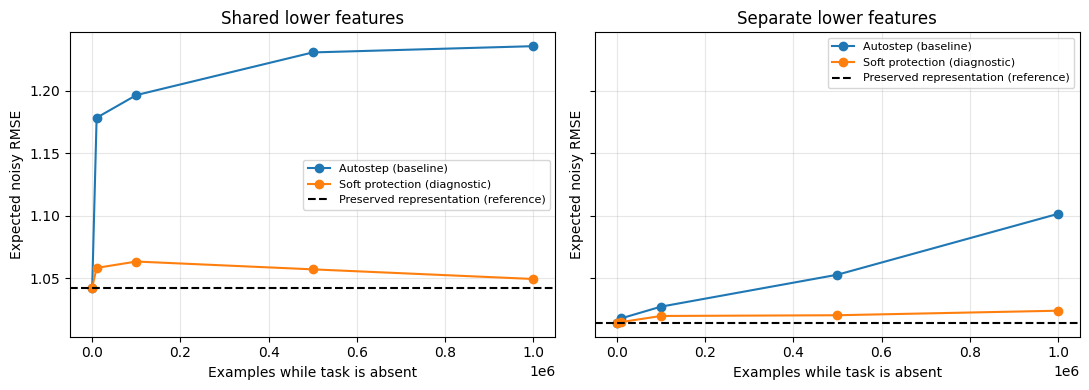

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (shared, result) in zip(axes, retention_results.items()):
    for method, label in enumerate(('Autostep (baseline)', 'Soft protection (diagnostic)')):
        ax.plot(result['gaps'], result['scores'][:, method, :, 1].mean(1), 'o-', label=label)
    reference = result['scores'][0, 0, :, 1].mean()
    ax.axhline(reference, color='black', ls='--', label='Preserved representation (reference)')
    ax.set(title='Shared lower features' if shared else 'Separate lower features',
           xlabel='Examples while task is absent', ylabel='Expected noisy RMSE')
    ax.grid(True, alpha=.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for shared, result in retention_results.items():
    print('Shared' if shared else 'Separate', 'active-task final RMSE:', result['scores'][-1, :, :, 0].mean(1))


**Initial observation, now qualified by the controls below.** These smaller networks lose absent-task accuracy relative to preserving the learned model. Soft prediction protection reduces that loss. This establishes a behavioral gap for these configurations; it does not establish failure with ample practical capacity or identify a complete mechanism.


## Main question: why does the smaller network forget?

Start from two well-learned tasks sharing the lower teacher features: 30 seeds, 1.6M examples, alternating tasks every example. Learner widths are 15 → 30. Branch from the exact same weights, optimizer state and normalization state, then train only the first task for 200k examples. Query both original tasks without learning. All controls use paired inputs and noise.

The absent readout is fixed in **every** control. The active readout keeps learning. Autostep state still updates in frozen layers, but their weight updates are discarded; their step-size changes are counterfactual, not evidence of actual weight learning. “Freeze a layer” means freeze its input weights, bias and normalization state; it does not freeze layers below it. Thus freezing the upper layer does not guarantee its activations stay fixed when the lower layer changes.

| Control | What changes during the absence? | What it checks |
| --- | --- | --- |
| Ordinary | Both hidden layers and their normalization state; active readout; noisy teacher targets | Observed forgetting |
| No target noise | Same, but use noise-free teacher targets | Whether observation noise is necessary |
| Lower layer frozen | Only upper hidden layer/state and active readout learn | Whether lower-layer drift is necessary |
| Upper layer frozen | Only lower hidden layer/state and active readout learn | Whether upper-weight changes are necessary |
| Both hidden layers frozen | Only active readout learns | Exact achievable preservation reference |
| Saved-model target + noise | Both hidden layers learn; target is the saved model's active prediction plus noise | Remove the need to improve the original active-task fit |
| Saved-model target, no noise | Same saved-model target, without noise | Residual drift from online statistics and learning dynamics |

The saved-model controls **change the active problem**; they diagnose a cause and are not proposed solutions. Their scores below still evaluate the original teachers. Normalization statistics continue updating in unfrozen layers, even for noiseless saved-model targets.


In [13]:
started = time.perf_counter()
old, teachers, keys = ready(initialize(True, nseeds=30))
learners, rngs, acquisition = ready(train(repeat(old, 1), None, teachers, keys[None],
                                         1_600_000, 'all', jnp.array([0]), period=1))
old = jax.tree.map(lambda a: a[0], learners)
keys = rngs[0]
acquisition_seconds = time.perf_counter() - started
print(f'Initial learning: {acquisition_seconds:.1f}s; old-task expected RMSE:',
      np.asarray(ready(evaluate(learners, teachers))).mean(1))


Initial learning: 51.5s; old-task expected RMSE: [[1.0346329 1.0386494]]


In [12]:
def diagnostic_forward(weights, x, learner, rates):
    sources, means, slopes, covs = [], [], [], []
    for w, mean, slope, cov, rate in zip(weights[:-1], learner.means, learner.slopes, learner.covs, rates):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        bits = ltu(z)
        mean = mean + rate * (jax.lax.stop_gradient(bits) - mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient((sigmoid * (1 - sigmoid))[:, None] * source)
        slope = slope + rate * (derivative - slope)
        correction = jnp.sum(slope * w, axis=1)
        centered = jax.lax.stop_gradient(bits - mean)
        h = bits - mean + (jax.lax.stop_gradient(correction) - correction)
        cov = cov + rate * (centered[:, None] * (derivative - slope) - cov)
        var = mean * (1 - mean)
        change = jnp.sum(cov * w, axis=1)
        floored = jnp.maximum(var, VAR_FLOOR)
        h = h - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / floored, 0.)
        x = h / jnp.sqrt(floored)
        means.append(mean); slopes.append(slope); covs.append(cov)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes), tuple(covs))


def diagnostic_update(l,x,y,freeze):
 def loss(w):
  pred,aux=diagnostic_forward(w,x,l,tuple(jnp.where(f,0.,EMA_RATE) for f in freeze))
  return .5*jnp.sum((pred[:OUTPUTS]-y)**2),aux
 (_, (sources,*stats)),g=jax.value_and_grad(loss,has_aux=True)(l.weights)
 g=(*g[:-1],g[-1].at[OUTPUTS:].set(0.))
 u,opt=OPT.update((g,None,sources),l.opt,l.weights)
 weights=tuple(jnp.where(f,a,a+b) for f,a,b in zip((*freeze,False),l.weights,u))
 return Learner(weights,opt,*stats)

def diagnose_retention(old, teachers, keys, steps=200_000):
    started=time.perf_counter()
    frozen=jnp.array([[0,0],[0,0],[1,0],[0,1],[1,1],[0,0],[0,0]],dtype=bool)
    noises=jnp.array([1.,0.,1.,1.,1.,1.,0.])
    self_targets=jnp.array([0,0,0,0,0,1,1],dtype=bool)
    @jax.jit
    def advance(ls,ks):
        def one(l,k,t,anchor,freeze,noise,self_target):
            def sample(c,_):
                l,k=c;k,kx,kn=jax.random.split(k,3)
                x=jax.random.rademacher(kx,(INPUTS,),dtype=jnp.float32)
                signal=jnp.where(self_target,predict(anchor,x)[:OUTPUTS],target(jax.tree.map(lambda a:a[0],t),x))
                y=signal+noise*jax.random.normal(kn,(OUTPUTS,))
                return (diagnostic_update(l,x,y,freeze),k),None
            return jax.lax.scan(sample,(l,k),None,length=10000)[0]
        return jax.vmap(jax.vmap(one,in_axes=(0,0,0,0,None,None,None)),in_axes=(0,0,None,None,0,0,0))(ls,ks,teachers,old,frozen,noises,self_targets)
    ls=repeat(old,7);ks=jnp.stack([keys]*7);scores=[];rates=[]
    for i in range(steps // 10_000 + 1):
        scores.append(np.asarray(ready(evaluate(ls,teachers))))
        rates.append([np.asarray(jnp.median(a,axis=(-2,-1))) for a in ls.opt.beta[:-1]])
        if i < steps // 10_000:ls,ks=ready(advance(ls,ks))
    result=dict(scores=np.asarray(scores),log_rates=np.asarray(rates),seconds=time.perf_counter()-started)
    np.testing.assert_array_equal(result['scores'][0,4,:,1],result['scores'][-1,4,:,1])
    assert np.isfinite(result['scores']).all()
    return result

diagnosis = diagnose_retention(old, teachers, keys)
diagnostic_labels = ['Ordinary', 'No target noise', 'Lower layer frozen', 'Upper layer frozen',
                     'Both hidden layers frozen', 'Saved-model target + noise', 'Saved-model target, no noise']
print('Final RMSE [active original task, absent original task]:')
for label, score in zip(diagnostic_labels, diagnosis['scores'][-1].mean(1)):
    print(label, score)
print('Change in median log step size, layer x control:',
      (diagnosis['log_rates'][-1]-diagnosis['log_rates'][0]).mean(-1))
print(f'Diagnostic controls: {diagnosis["seconds"]:.1f}s')


Final RMSE [active original task, absent original task]:
Ordinary [1.0233722 1.1128463]
No target noise [1.014225  1.1049311]
Lower layer frozen [1.0232811 1.1031705]
Upper layer frozen [1.0451744 1.0569513]
Both hidden layers frozen [1.0316793 1.0386494]
Saved-model target + noise [1.0448312 1.0548631]
Saved-model target, no noise [1.0370933 1.0469226]
Change in median log step size, layer x control: [[-0.03067617  0.00424562  0.02628322  0.00871836  0.09948438 -0.04718564
  -0.00520902]
 [-0.01375931  0.05141538 -0.06619304  0.17756619  0.14002277 -0.04410097
   0.00949637]]
Diagnostic controls: 13.7s


**Capacity control.** Increase widths from 15 → 30 to 45 → 90, leaving teachers, optimizer settings and initial learning duration unchanged. Use five paired seeds for the width comparison and continue the larger learner to a 1M-example absence. The preserved reference freezes both hidden layers and their statistics while still training the active readout. This tests practical capacity, not just whether the teacher functions can theoretically fit.


In [14]:
@partial(jax.jit, static_argnames=('shared', 'nseeds', 'ntasks'))
def initialize_wide(shared, nseeds=5, ntasks=2):
    def one(seed):
        kt, kl, rng = jax.random.split(jax.random.PRNGKey(seed), 3)
        kf, ks = jax.random.split(kt)
        groups = 1 if shared else ntasks
        first = jax.random.rademacher(kf, (groups, FEATURES, INPUTS), dtype=jnp.float32)
        first = jnp.repeat(first, ntasks, axis=0) if shared else first
        teachers = (first, *jax.vmap(make_task)(jax.random.split(ks, ntasks), first))
        widths = (45 * groups, 45 * ntasks)
        weights, fan_in = [], INPUTS
        for key, width in zip(jax.random.split(kl), widths):
            w = INIT_RATE * jax.random.uniform(key, (width, fan_in + 1), minval=-1., maxval=1.).at[:, -1].set(0.)
            weights.append(w)
            fan_in = width
        weights = (*weights, jnp.zeros((ntasks * OUTPUTS, fan_in + 1)))
        learner = Learner(weights, OPT.init(weights),
                          tuple(jnp.full(len(w), .5) for w in weights[:-1]),
                          tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]),
                          tuple(jnp.zeros_like(w) for w in weights[:-1]))
        return learner, teachers, rng
    return jax.vmap(one)(jnp.arange(nseeds))



def wide_retention(shared=True):
    started=time.perf_counter()
    l,t,k=ready(initialize_wide(shared,5))
    ls,ks,_=ready(train(repeat(l,1),None,t,k[None],1_600_000,'all',jnp.array([0]),period=1 if shared else 10_000))
    anchor=jax.tree.map(lambda a:a[0],ls)
    starting_keys=ks[0]
    ls=repeat(anchor,2);ks=jnp.repeat(ks,2,axis=0);scores=[];rates=[];movement=[]
    for i in range(21):
        scores.append(np.asarray(ready(evaluate(ls,t))))
        rates.append([np.asarray(jnp.median(a,axis=(-2,-1))) for a in ls.opt.beta[:-1]])
        movement.append([np.asarray(jnp.sqrt(jnp.mean((a-b[None])**2,axis=(-2,-1)))) for a,b in zip(ls.weights[:-1],anchor.weights[:-1])])
        if i<20:ls,ks,_=ready(train(ls,None,t,ks,50_000,'0',jnp.array([0,2])))
    result=dict(scores=np.asarray(scores),log_rates=np.asarray(rates),movement=np.asarray(movement),seconds=time.perf_counter()-started)
    np.testing.assert_array_equal(result['scores'][0,1,:,1],result['scores'][-1,1,:,1])
    print('Wide initial/final task RMSE:',result['scores'][0].mean(1),result['scores'][-1].mean(1))
    print('Wide weight displacement, layer x method:',result['movement'][-1].mean(-1))
    print(f'Wide retention: {result["seconds"]:.1f}s')
    result.update(anchor=anchor, teachers=t, keys=starting_keys, final=ls)
    return result

wide_diagnosis = wide_retention()


Wide initial/final task RMSE: [[1.0143477 1.0118568]
 [1.0143477 1.0118568]] [[1.0062771 1.0083901]
 [1.012345  1.0118568]]
Wide weight displacement, layer x method: [[0.10689904 0.        ]
 [0.05621886 0.        ]]
Wide retention: 102.7s


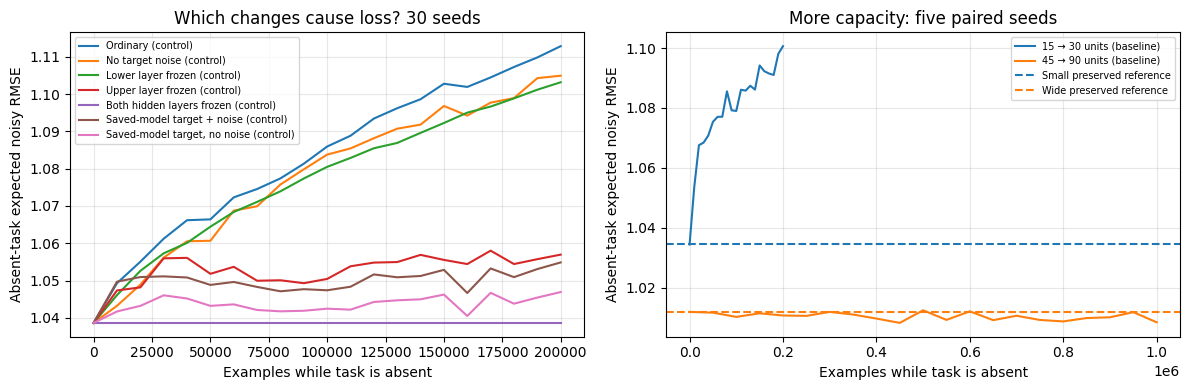

In [15]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for i,label in enumerate(diagnostic_labels):
    axes[0].plot(np.arange(21)*10_000,diagnosis['scores'][:,i,:,1].mean(1),label=label+' (control)')
axes[0].set(title='Which changes cause loss? 30 seeds',xlabel='Examples while task is absent')
axes[1].plot(np.arange(21)*10_000,diagnosis['scores'][:,0,:5,1].mean(1),label='15 → 30 units (baseline)')
axes[1].plot(np.arange(21)*50_000,wide_diagnosis['scores'][:,0,:,1].mean(1),label='45 → 90 units (baseline)')
for values,label,color in ((diagnosis['scores'][0,0,:5,1],'Small preserved reference','C0'),
                           (wide_diagnosis['scores'][0,0,:,1],'Wide preserved reference','C1')):
    axes[1].axhline(values.mean(),ls='--',color=color,label=label)
axes[1].set(title='More capacity: five paired seeds',xlabel='Examples while task is absent')
for ax in axes:
    ax.set_ylabel('Absent-task expected noisy RMSE');ax.grid(True,alpha=.3);ax.legend(fontsize=7)
fig.tight_layout();plt.show()


**Separate lower features with ample capacity.** Use 90 → 90 units and the original 10k-example acquisition blocks for 1.6M examples. Alternating every example left these tasks poorly learned (RMSE about 1.37 before absence), so it was not a clean retention test. With the established block schedule, the absent task starts near 1.018 and rises to 1.032 after 1M examples. Extra capacity therefore does not eliminate every retention gap.

Repeat the same controls from that learned checkpoint for 500k examples, using five paired seeds per configuration. Here the pattern changes: removing noise or freezing the lower layer almost closes the gap; freezing the upper layer does not. This is the cleaner case to use when investigating the missing upstream normalization correction. It is evidence consistent with that mechanism, not yet a test showing that repairing the derivative fixes retention.


In [17]:
wide_separate = wide_retention(shared=False)


Wide initial/final task RMSE: [[1.0156876 1.0175235]
 [1.0156876 1.0175235]] [[1.008811  1.0324061]
 [1.0136839 1.0175235]]
Wide weight displacement, layer x method: [[0.16795948 0.        ]
 [0.04308186 0.        ]]
Wide retention: 100.8s


Wide, separate features: final original-task RMSE [active, absent]
Ordinary [1.0107267 1.0274016]
No target noise [1.000798  1.0189371]
Lower layer frozen [1.0138098 1.0182917]
Upper layer frozen [1.0097988 1.0370085]
Both hidden layers frozen [1.0139052 1.0175489]
Saved-model target + noise [1.0181543 1.0271622]
Saved-model target, no noise [1.0167224 1.0176935]
Median log-rate change, layer x control: [[-0.03752661  0.0003274  -0.00215092 -0.03805494  0.01006155 -0.0488265
  -0.00648603]
 [-0.05451565 -0.00229645 -0.05530014 -0.04163093 -0.01717796 -0.06381188
  -0.00702724]]
Wide controls: 33.5s


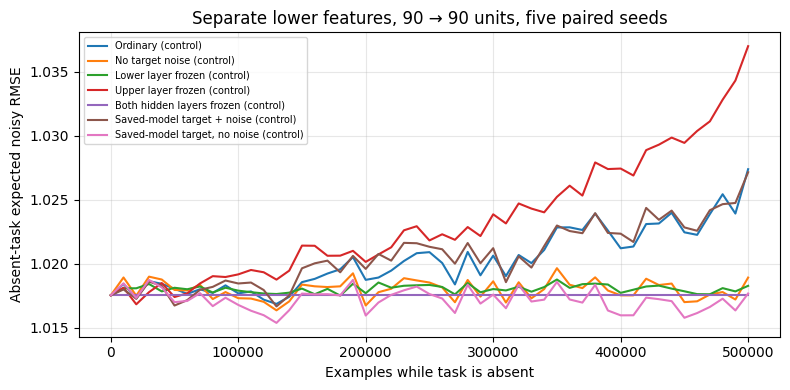

In [18]:
wide_controls = diagnose_retention(wide_separate['anchor'], wide_separate['teachers'], wide_separate['keys'], steps=500_000)
print('Wide, separate features: final original-task RMSE [active, absent]')
for label, score in zip(diagnostic_labels, wide_controls['scores'][-1].mean(1)):
    print(label, score)
print('Median log-rate change, layer x control:',
      (wide_controls['log_rates'][-1]-wide_controls['log_rates'][0]).mean(-1))
print(f'Wide controls: {wide_controls["seconds"]:.1f}s')
fig,ax=plt.subplots(figsize=(8,4))
for i,label in enumerate(diagnostic_labels):
    ax.plot(np.arange(51)*10_000,wide_controls['scores'][:,i,:,1].mean(1),label=label+' (control)')
ax.set(xlabel='Examples while task is absent',ylabel='Absent-task expected noisy RMSE',
       title='Separate lower features, 90 → 90 units, five paired seeds')
ax.grid(True,alpha=.3);ax.legend(fontsize=7);fig.tight_layout();plt.show()


**Do the absent task's actual features get smaller step sizes?** Match each of its ten true lower features to the learner unit with the highest absolute firing correlation on 4,096 fixed inputs. This selects ten distinct units in every seed, with mean correlation 0.998 before absence. Reuse those same units after 1M updates; mean correlation falls to 0.993. This measurement complements the task errors above.

For each selected unit, compare the median step size across its incoming weights before and after absence. Ratios range from **0.9987 to 1.0017**, with median **0.9999**. These particular learned features' rates are essentially unchanged, even though their firing patterns drift. Layer-wide averages obscured this distinction. This does not yet explain which part of Autostep's trace dynamics prevents useful rate reduction.


In [20]:
x=jax.random.rademacher(jax.random.PRNGKey(219),(4096,INPUTS),dtype=jnp.float32)
@jax.jit
def check(old,t,final):
 def one(l,t,f):
  before=(x@l.weights[0][:,:-1].T+l.weights[0][:,-1]>0).astype(jnp.float32)
  after=(x@f.weights[0][:,:-1].T+f.weights[0][:,-1]>0).astype(jnp.float32)
  truth=(x@t[0][1].T>2).astype(jnp.float32)
  def corr(a,b):
   a=a-a.mean(0);b=b-b.mean(0)
   return a.T@b/jnp.sqrt(jnp.maximum((a*a).sum(0)[:,None]*(b*b).sum(0)[None,:],1e-20))
  c=corr(before,truth);indices=jnp.abs(c).argmax(0)
  initial=jnp.abs(c[indices,jnp.arange(FEATURES)])
  later=jnp.abs(corr(after,truth)[indices,jnp.arange(FEATURES)])
  ratio=jnp.exp(jnp.median(f.opt.beta[0][indices],axis=-1)-jnp.median(l.opt.beta[0][indices],axis=-1))
  return indices,initial,later,ratio
 return jax.vmap(one)(old,t,jax.tree.map(lambda a:a[0],final))
indices,before,after,ratio=ready(check(wide_separate['anchor'],wide_separate['teachers'],wide_separate['final']))
print('Mean best-match correlation before/after',before.mean(),after.mean())
print('Matched old-feature unit median-rate ratios: median/min/max',jnp.median(ratio),ratio.min(),ratio.max())
print('Fraction rate ratios below .5 / above 1',(ratio<.5).mean(),(ratio>1).mean())
print('Distinct selected units by seed',[len(set(a.tolist())) for a in np.asarray(indices)])


Mean best-match correlation before/after 0.9984405 0.99340224
Matched old-feature unit median-rate ratios: median/min/max 0.99993443 0.99865144 1.0017304
Fraction rate ratios below .5 / above 1 0.0 0.34
Distinct selected units by seed [10, 10, 10, 10, 10]


**A separate normalization-gradient check.** A standardized scalar has mean squared value 1, so its half-squared loss is 0.5 regardless of its input weights. Its gradient should be zero. On 8,192 fixed inputs per seed, compute exact moments to remove EMA estimation error. Compare our local weight correction with differentiating through all normalization moments. Use the same LTU surrogate in both cases.

The one-layer correction passes to numerical accuracy. In two layers it leaves a lower-layer gradient around 0.002 RMS; differentiating all moments reduces it to about 1e-10. The current code accounts for normalization changes caused by a unit's own weights, but misses changes caused by earlier layers. This is an implementation flaw. It does not explain all forgetting: the upper layer still forgets when the lower layer is frozen.


In [17]:
x=jax.random.rademacher(jax.random.PRNGKey(432),(8192,INPUTS),dtype=jnp.float32)
def standardized(w,x,local):
 source=jnp.concatenate((x,jnp.ones((len(x),1))),axis=1)
 z=source@w.T;bits=ltu(z);mean=bits.mean(0);centered=bits-mean;var=(centered**2).mean(0)
 if not local:return centered/jnp.sqrt(jnp.maximum(var,VAR_FLOOR))
 mean,var=jax.lax.stop_gradient((mean,var))
 derivative=jax.lax.stop_gradient((jax.nn.sigmoid(z)*(1-jax.nn.sigmoid(z)))[:,:,None]*source[:,None,:])
 slope=derivative.mean(0)
 covariance=jax.lax.stop_gradient(((bits-mean)[:,:,None]*(derivative-slope)).mean(0))
 correction=(slope*w).sum(-1);change=(covariance*w).sum(-1)
 h=bits-mean+(jax.lax.stop_gradient(correction)-correction)
 h=h-jax.lax.stop_gradient(bits-mean)*jnp.where(var>VAR_FLOOR,(change-jax.lax.stop_gradient(change))/jnp.maximum(var,VAR_FLOOR),0.)
 return h/jnp.sqrt(jnp.maximum(var,VAR_FLOOR))
def one(w,means,local,depth):
 selected=jnp.argmin(jnp.abs(means[depth-1]-.5))
 def loss(ws):
  h=x
  for weight in ws[:depth]:h=standardized(weight,h,local)
  return .5*jnp.mean(h[:,selected]**2)
 value,g=jax.value_and_grad(loss)(w)
 return value,jnp.stack([jnp.sqrt(jnp.mean(a*a)) for a in g[:-1]])
start=time.perf_counter();normalization_results={}
for depth in (1,2):
 for local in (True,False):
  f=jax.jit(jax.vmap(lambda w,m:one(w,m,local,depth)))
  value,g=ready(f(old.weights,old.means))
  normalization_results[(depth,local)]=(np.asarray(value),np.asarray(g))
  print('depth',depth,'local normalization gradient',local,'loss',value.mean(),'gradient RMS by layer',g.mean(0),flush=True)


depth 1 local normalization gradient True loss 0.5000001 gradient RMS by layer [1.6358047e-07 0.0000000e+00]
depth 1 local normalization gradient False loss 0.5 gradient RMS by layer [4.3700496e-10 0.0000000e+00]
depth 2 local normalization gradient True loss 0.5 gradient RMS by layer [1.9597076e-03 9.7447196e-07]
depth 2 local normalization gradient False loss 0.5 gradient RMS by layer [1.3038462e-10 2.6548397e-10]


## Local backward correction: paired retention test

Replace the old parameter-specific correction with a custom backward at each standardization operation. Each unit tracks the mean incoming error and its product with its standardized activation (EMA rate 0.001). It subtracts these terms before propagating error to its own weights and the layer below. These are local signals. Running traces approximate the exact-moment rule; this is not exact differentiation through EMA state. A 30-seed exact-moment backward check matched the reference to within 9.6e-7.

Three methods start from the same learned 90 → 90 separate-feature checkpoint, including Autostep state, and receive identical noisy examples. Five paired seeds, one million absent-task examples. The baseline keeps the old correction. The proposed rule initializes its new error traces to zero, keeps Autostep unchanged and updates hidden weights and forward means; old derivative traces are unused. The preserved baseline freezes hidden weights, biases and normalization state; its active readout and optimizer state still update. Every method holds the absent readout fixed. This tests switching the backward rule after learning, not learning from scratch.

**Later qualification:** this changes the online own-weight update as well as upstream propagation. It is not a pure bug fix or a validated replacement for 01; see the reconciliation section below.


## Local backward correction: paired retention test

Replace the old parameter-specific correction with a custom backward at each standardization operation. Each unit tracks the mean incoming error and its product with its standardized activation (EMA rate 0.001). It subtracts these terms before propagating error to its own weights and the layer below. These are local signals. Running traces approximate the exact-moment rule; this is not exact differentiation through EMA state. A 30-seed exact-moment backward check matched the reference to within 9.6e-7.

Three methods start from the same learned 90 → 90 separate-feature checkpoint, including Autostep state, and receive identical noisy examples. Five paired seeds, one million absent-task examples. The baseline keeps the old correction. The proposed rule initializes its new error traces to zero, keeps Autostep unchanged and updates hidden weights and forward means; old derivative traces are unused. The preserved baseline freezes hidden weights, biases and normalization state; its active readout and optimizer state still update. Every method holds the absent readout fixed. This tests switching the backward rule after learning, not learning from scratch.


Initial RMSE [active, absent]: [1.0156876 1.0175235]
Baseline: original correction [1.008811  1.0324061]
Proposed: local backward [1.0066669 1.0292506]
Baseline: frozen hidden [1.0136839 1.0175235]
Runtime: 60.9s


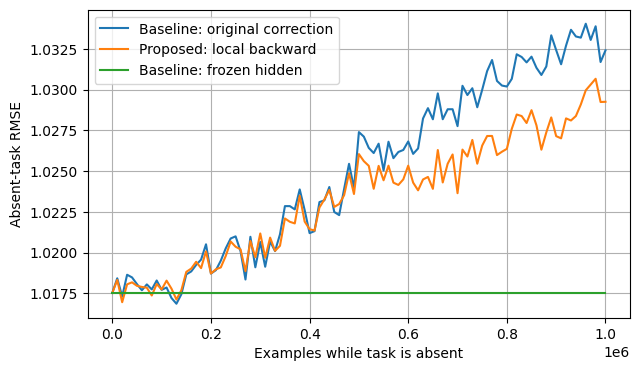

In [24]:
@jax.custom_vjp
def local_standardize(bits, mean, error_mean, error_product_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def _standardize_forward(bits, mean, error_mean, error_product_mean):
    var = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(var, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, var > VAR_FLOOR, error_mean, error_product_mean)


def _standardize_backward(saved, g):
    h, scale, scale_active, error_mean, error_product_mean = saved
    corrected = (g - error_mean - jnp.where(scale_active, h * error_product_mean, 0.)) / scale
    return corrected, None, None, None


local_standardize.defvjp(_standardize_forward, _standardize_backward)


def local_update(learner, traces, x, y):
    # Forward values match the baseline; replace its parameter-specific correction.
    sources, means, bits_list, activations = [], [], [], []
    for w, mean in zip(learner.weights[:-1], learner.means):
        source = jnp.append(x, 1.)
        bits = ltu(w @ source)
        mean = mean + EMA_RATE * (bits - mean)
        x = (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))
        sources.append(source); means.append(mean)
        bits_list.append(bits); activations.append(x)
    source = jnp.append(x, 1.)
    error = (learner.weights[-1] @ source)[:OUTPUTS] - y
    output_error = jnp.pad(error, (0, learner.weights[-1].shape[0] - OUTPUTS))
    grads = [output_error[:, None] * source]
    g = learner.weights[-1][:, :-1].T @ output_error
    updated_traces = []
    for i in reversed(range(len(means))):
        eg, egh = traces[i]
        eg = eg + EMA_RATE * (g - eg)
        egh = egh + EMA_RATE * (g * activations[i] - egh)
        _, backward = jax.vjp(lambda b: local_standardize(b, means[i], eg, egh), bits_list[i])
        db = backward(g)[0]
        sigmoid = jax.nn.sigmoid(learner.weights[i] @ sources[i])
        dz = db * sigmoid * (1 - sigmoid)  # Existing LTU surrogate.
        grads.insert(0, dz[:, None] * sources[i])
        g = learner.weights[i][:, :-1].T @ dz
        updated_traces.insert(0, (eg, egh))
    inputs = tuple(a[None] for a in (*sources, source))
    updates, opt = OPT.update((tuple(grads), None, inputs), learner.opt, learner.weights)
    weights = jax.tree.map(jnp.add, learner.weights, updates)
    # Old derivative traces are unused by this rule.
    return Learner(weights, opt, tuple(means), learner.slopes, learner.covs), tuple(updated_traces)


def compare_local_backward(anchor, teachers, keys, steps=1_000_000):
    started = time.perf_counter()
    traces = tuple((jnp.zeros_like(m), jnp.zeros_like(m)) for m in anchor.means)
    @jax.jit
    def advance(learners, traces, keys):
        def one(ls, tr, key, teacher):
            def sample(carry, _):
                baseline, proposed, frozen, tr, key = carry
                key, kx, kn = jax.random.split(key, 3)
                x = jax.random.rademacher(kx, (INPUTS,), dtype=jnp.float32)
                y = target(jax.tree.map(lambda a: a[0], teacher), x) + jax.random.normal(kn, (OUTPUTS,))
                baseline, _ = update(baseline, None, x, y, 0, 0)
                proposed, tr = local_update(proposed, tr, x, y)
                frozen, _ = update(frozen, None, x, y, 0, 2)
                return (baseline, proposed, frozen, tr, key), None
            return jax.lax.scan(sample, (*ls, tr, key), None, length=10_000)[0]
        b, p, f, traces, keys = jax.vmap(one)(learners, traces, keys, teachers)
        return (b, p, f), traces, keys
    learners = (anchor, anchor, anchor)
    scores = []
    for i in range(steps // 10_000 + 1):
        stacked = jax.tree.map(lambda *a: jnp.stack(a), *learners)
        scores.append(np.asarray(ready(evaluate(stacked, teachers))))
        if i < steps // 10_000:
            learners, traces, keys = ready(advance(learners, traces, keys))
    scores = np.asarray(scores)
    assert np.isfinite(scores).all()
    np.testing.assert_array_equal(scores[0, 2, :, 1], scores[-1, 2, :, 1])
    return dict(scores=scores, seconds=time.perf_counter()-started)


local_comparison = compare_local_backward(wide_separate['anchor'], wide_separate['teachers'], wide_separate['keys'])
print('Initial RMSE [active, absent]:', local_comparison['scores'][0, 0].mean(0))
for label, values in zip(['Baseline: original correction', 'Proposed: local backward', 'Baseline: frozen hidden'], local_comparison['scores'][-1]):
    print(label, values.mean(0))
print(f"Runtime: {local_comparison['seconds']:.1f}s")
fig, ax = plt.subplots(figsize=(7, 4))
for i, label in enumerate(['Baseline: original correction', 'Proposed: local backward', 'Baseline: frozen hidden']):
    ax.plot(np.arange(len(local_comparison['scores'])) * 10_000, local_comparison['scores'][:, i, :, 1].mean(1), label=label)
ax.set(xlabel='Examples while task is absent', ylabel='Absent-task RMSE')
ax.grid(); ax.legend(); plt.show()


Absent-task RMSE starts at **1.01752**. After one million examples: original correction **1.03241**, local backward **1.02925**, preserved reference **1.01752**. Active-task RMSE is respectively **1.00881**, **1.00667**, and **1.01368**. Runtime: 60.9s.

This finite-duration comparison tests the online approximation; exact-statistics backward correctness alone does not establish indefinite retention.


**No backward correction baseline.** Same five learned checkpoints, Autostep state, noisy examples and 1M-example absence. Forward standardization and its running means still update, but backward treats those moments as constants. Both hidden layers and the active readout learn; the absent readout stays fixed. This switches the rule after acquisition, as above.


In [25]:
# Forward standardization is identical. Treat running moments as constants in backward.
def uncorrected_update(l,x,y):
 def loss(weights):
  a=x;sources=[];means=[]
  for w,mean in zip(weights[:-1],l.means):
   source=jnp.append(a,1.);sources.append(source[None])
   bits=ltu(w@source)
   mean=jax.lax.stop_gradient(mean+EMA_RATE*(bits-mean))
   means.append(mean)
   a=(bits-mean)/jnp.sqrt(jnp.maximum(mean*(1-mean),VAR_FLOOR))
  source=jnp.append(a,1.);sources.append(source[None])
  return .5*jnp.sum(((weights[-1]@source)[:OUTPUTS]-y)**2),(tuple(sources),tuple(means))
 (_, (sources,means)),g=jax.value_and_grad(loss,has_aux=True)(l.weights)
 u,opt=OPT.update((g,None,sources),l.opt,l.weights)
 return Learner(jax.tree.map(jnp.add,l.weights,u),opt,means,l.slopes,l.covs)
@jax.jit
def advance_uncorrected(ls,keys,teachers):
 def one(l,k,t):
  def sample(c,_):
   l,k=c;k,kx,kn=jax.random.split(k,3)
   x=jax.random.rademacher(kx,(INPUTS,),dtype=jnp.float32)
   y=target(jax.tree.map(lambda a:a[0],t),x)+jax.random.normal(kn,(OUTPUTS,))
   return (uncorrected_update(l,x,y),k),None
  return jax.lax.scan(sample,(l,k),None,length=10000)[0]
 return jax.vmap(one)(ls,keys,teachers)
started=time.perf_counter();l=wide_separate['anchor'];scores=[]
keys=wide_separate['keys'];teachers=wide_separate['teachers']
for i in range(101):
 scores.append(np.asarray(ready(evaluate(repeat(l,1),teachers)))[0])
 if i<100:l,keys=ready(advance_uncorrected(l,keys,teachers))
no_correction_result=dict(scores=np.asarray(scores),seconds=time.perf_counter()-started)
assert np.isfinite(no_correction_result['scores']).all()
print('Final RMSE [active, absent]:', no_correction_result['scores'][-1].mean(0))
print('Seconds:', no_correction_result['seconds'])


Final RMSE [active, absent]: [1.0089487 1.0430256]
Seconds: 23.522440721999374


## Retention with the exact shared lower features

The smaller 15 → 30 network receives all ten true shared lower features. Its original five extra lower units are also retained. All lower weights, biases and normalization statistics stay fixed throughout. True features use their exact population firing means; extras use the existing calibration inputs. Upper weights, biases, normalization means and local error traces learn using the local backward correction from initialization. Autostep settings and target noise (standard deviation 1) are unchanged.

Thirty seeds learn both tasks for 1.6M examples, alternating tasks every example. Then only task 0 appears for 1M examples, followed by a 3M-example continuation. Only the active readout learns. The preserved baseline is the acquired model held completely fixed; its absent-task RMSE stays constant. Neither old-task labels nor preserved-model predictions enter subsequent updates. Bands are mean ±1.96 standard errors across 30 seeds. Each acquisition/continuation run takes under two minutes.

An initial check used 10k-example acquisition blocks: the final block left task RMSEs at 1.187 and 1.022, followed by absent-task RMSE 1.274 at 1M and 1.337 at 4M. The alternating-example comparison below removes that large initial task imbalance. Both starting errors still exceed the noise floor; it does not assume perfect acquisition.


In [26]:
def fixed_lower_update(l, traces, x, y, task):
    w0, w1, wo = l.weights
    m0, m1 = l.means
    lower = (ltu(w0[:, :-1] @ x + w0[:, -1]) - m0) / jnp.sqrt(jnp.maximum(m0 * (1 - m0), VAR_FLOOR))
    source = jnp.append(lower, 1.)
    bits = ltu(w1 @ source)
    m1 = m1 + EMA_RATE * (bits - m1)
    h = (bits - m1) / jnp.sqrt(jnp.maximum(m1 * (1 - m1), VAR_FLOOR))
    out_source = jnp.append(h, 1.)
    prediction = (wo @ out_source).reshape(2, OUTPUTS)
    error = jnp.zeros_like(prediction).at[task].set(prediction[task] - y).reshape(-1)
    g = wo[:, :-1].T @ error
    eg, egh = traces
    eg = eg + EMA_RATE * (g - eg)
    egh = egh + EMA_RATE * (g * h - egh)
    _, backward = jax.vjp(lambda b: local_standardize(b, m1, eg, egh), bits)
    sigmoid = jax.nn.sigmoid(w1 @ source)
    dz = backward(g)[0] * sigmoid * (1 - sigmoid)
    grads = (jnp.zeros_like(w0), dz[:, None] * source, error[:, None] * out_source)
    inputs = (jnp.append(x, 1.)[None], source[None], out_source[None])
    updates, opt = OPT.update((grads, None, inputs), l.opt, l.weights)
    weights = (w0, w1 + updates[1], wo + updates[2])
    return Learner(weights, opt, (m0, m1), l.slopes, l.covs), (eg, egh)


@jax.jit
def fixed_lower_chunk(learners, traces, keys, teachers, task):
    def one(l, tr, key, teacher):
        def sample(carry, i):
            l, tr, key = carry
            active = jnp.where(task < 0, i % 2, task)
            key, kx, kn = jax.random.split(key, 3)
            x = jax.random.rademacher(kx, (INPUTS,), dtype=jnp.float32)
            y = target(jax.tree.map(lambda a: a[active], teacher), x) + jax.random.normal(kn, (OUTPUTS,))
            l, tr = fixed_lower_update(l, tr, x, y, active)
            return (l, tr, key), None
        return jax.lax.scan(sample, (l, tr, key), jnp.arange(10_000))[0]
    return jax.vmap(one, in_axes=(0, 0, 0, 0))(learners, traces, keys, teachers)


def fixed_lower_experiment():
    from math import comb
    started = time.perf_counter()
    l, teachers, keys = ready(initialize(True, nseeds=30))
    w0 = l.weights[0].at[:, :FEATURES, :-1].set(teachers[0][:, 0])
    w0 = w0.at[:, :FEATURES, -1].set(-2.)
    # Keep the original five extra features, fixed; calibrate their means once.
    m0 = jax.vmap(lambda w: (w[:, :-1] @ CALIBRATION.T + w[:, -1, None] > 0).mean(1))(w0)
    firing = sum(comb(INPUTS, k) for k in range(12, INPUTS + 1)) / 2**INPUTS
    m0 = m0.at[:, :FEATURES].set(firing)
    weights = (w0, *l.weights[1:])
    l = l._replace(weights=weights, opt=jax.vmap(OPT.init)(weights), means=(m0, l.means[1]))
    traces = (jnp.zeros_like(l.means[1]), jnp.zeros_like(l.means[1]))
    for i in range(160):
        l, traces, keys = ready(fixed_lower_chunk(l, traces, keys, teachers, jnp.asarray(-1)))
    anchor = l
    anchor_traces, anchor_keys = traces, keys
    acquisition_seconds = time.perf_counter() - started
    print(f'Acquisition: {acquisition_seconds:.1f}s', flush=True)
    scores = [np.asarray(ready(evaluate(repeat(l, 1), teachers)))[0]]
    for i in range(100):
        l, traces, keys = ready(fixed_lower_chunk(l, traces, keys, teachers, jnp.asarray(0)))
        if (i + 1) % 5 == 0:
            scores.append(np.asarray(ready(evaluate(repeat(l, 1), teachers)))[0])
    np.testing.assert_array_equal(l.weights[0], anchor.weights[0])
    np.testing.assert_array_equal(l.means[0], anchor.means[0])
    np.testing.assert_array_equal(l.weights[-1][:, OUTPUTS:], anchor.weights[-1][:, OUTPUTS:])
    scores = np.asarray(scores)
    assert np.isfinite(scores).all()
    result = dict(scores=scores, anchor=anchor, anchor_traces=anchor_traces, anchor_keys=anchor_keys, final=l, traces=traces, keys=keys, teachers=teachers,
                  seconds=time.perf_counter()-started)
    print('Initial RMSE [active, absent]:', scores[0].mean(0))
    print('Final RMSE [active, absent]:', scores[-1].mean(0))
    print(f'Total: {result["seconds"]:.1f}s')
    return result


fixed_lower_result = fixed_lower_experiment()


Initial RMSE [active, absent]: [1.0778884 1.0804727]
Final RMSE [active, absent]: [1.0167686 1.2545955]
Total: 66.5s


After 2M, 3M, 4M [active, absent]: [[1.010772  1.2835562]
 [1.0091282 1.2984043]
 [1.0076414 1.3088118]]
Continuation: 70.2s


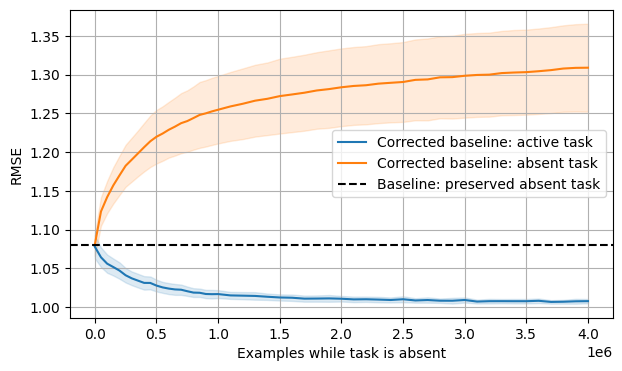

In [27]:
def extend_fixed_lower(result):
    started = time.perf_counter()
    l, traces, keys = result['final'], result['traces'], result['keys']
    scores = []
    for i in range(300):
        l, traces, keys = ready(fixed_lower_chunk(l, traces, keys, result['teachers'], jnp.asarray(0)))
        if (i + 1) % 10 == 0:
            scores.append(np.asarray(ready(evaluate(repeat(l, 1), result['teachers'])))[0])
    scores = np.asarray(scores)
    assert np.isfinite(scores).all()
    return dict(scores=scores, seconds=time.perf_counter()-started)


fixed_lower_extension = extend_fixed_lower(fixed_lower_result)
print('After 2M, 3M, 4M [active, absent]:', fixed_lower_extension['scores'][[9,19,29]].mean(1))
print(f"Continuation: {fixed_lower_extension['seconds']:.1f}s")
fig, ax = plt.subplots(figsize=(7, 4))
steps = np.concatenate((np.arange(21)*50_000, 1_000_000+np.arange(1,31)*100_000))
scores = np.concatenate((fixed_lower_result['scores'], fixed_lower_extension['scores']))
for task, label in enumerate(['Corrected baseline: active task', 'Corrected baseline: absent task']):
    values = scores[:, :, task]
    mean = values.mean(1); sem = values.std(1, ddof=1) / np.sqrt(30)
    line, = ax.plot(steps, mean, label=label)
    ax.fill_between(steps, mean-1.96*sem, mean+1.96*sem, alpha=.15, color=line.get_color())
ax.axhline(scores[0, :, 1].mean(), linestyle='--', color='black', label='Baseline: preserved absent task')
ax.set(xlabel='Examples while task is absent', ylabel='RMSE')
ax.grid(); ax.legend(); plt.show()


With the lower representation exact and fixed, absent-task RMSE rises from **1.080** to **1.255** at 1M and **1.309** at 4M examples. Active-task RMSE improves from **1.078** to **1.008**. The preserved reference stays at **1.080**.

This isolates a failure in the learned upper representation; changing lower features are not necessary for forgetting. It does not yet distinguish noise-driven drift from interference during further fitting, or establish an asymptotic trend. The upper layer has 30 units against a sufficient construction using 20, but the learner need not discover that construction. Next isolate noise versus continued fitting before deciding whether protection is warranted.


## Point 1: why the small network forgets

Use five paired seeds from the exact-lower-feature experiment, with identical learned weights, Autostep state and examples. All lower features remain fixed. Test 500k examples of task 0. The absent readout always stays fixed. The ordinary baseline uses the local backward rule; no protection method is proposed here.

- **No target noise:** keep the real active target but remove Gaussian noise.
- **Saved-model targets:** replace the active target with the acquired model's predictions, with or without fresh noise. The active problem is therefore already fitted at the start. This changes the problem deliberately; evaluation still uses the original teachers.
- **Upper frozen:** freeze upper weights, biases and normalization state too. Only the active readout learns; Autostep state still updates with zero hidden gradients.
- **01 backward rule:** replace the local error correction with the original per-weight derivative correction, initializing its derivative traces from the fixed calibration inputs. All other learning settings stay the same.

The readout check fits a new linear readout to noiseless targets on 16,384 inputs and evaluates on separate inputs. It is an approximate best-readout reference, not an online method. It changes neither hidden layer nor normalization state.


Initial: [1.070134  1.0937393]
Ordinary [1.0100496 1.2054191]
No target noise [1.0063677 1.1951144]
Saved-model target + noise [1.070952  1.0958792]
Saved-model target, no noise [1.0706917 1.094394 ]
Upper frozen [1.0671146 1.0937393]
01 backward rule [1.0107577 1.205066 ]
Control seconds 20.638418354999885
Initial optimal readouts [1.066625 1.090215]
Refitted ordinary: [1.0073912 1.1486566]


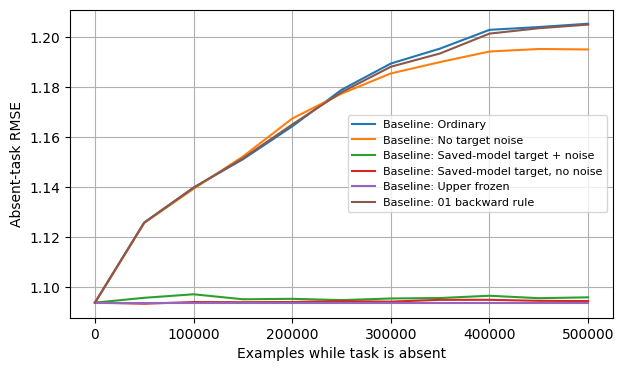

In [28]:
def old_rule(l,x,y):
 def loss(w):
  lower=(ltu(w[0][:,:-1]@x+w[0][:,-1])-l.means[0])/jnp.sqrt(jnp.maximum(l.means[0]*(1-l.means[0]),VAR_FLOOR))
  source=jnp.append(lower,1.);z=w[1]@source;bits=ltu(z)
  mean=l.means[1]+EMA_RATE*(jax.lax.stop_gradient(bits)-l.means[1])
  sig=jax.nn.sigmoid(z);d=jax.lax.stop_gradient((sig*(1-sig))[:,None]*source)
  slope=l.slopes[1]+EMA_RATE*(d-l.slopes[1]);c=jnp.sum(slope*w[1],axis=1)
  centered=jax.lax.stop_gradient(bits-mean);h=bits-mean+jax.lax.stop_gradient(c)-c
  cov=l.covs[1]+EMA_RATE*(centered[:,None]*(d-slope)-l.covs[1]);v=mean*(1-mean);vfloor=jnp.maximum(v,VAR_FLOOR)
  change=jnp.sum(cov*w[1],axis=1)
  h=(h-centered*jnp.where(v>VAR_FLOOR,(change-jax.lax.stop_gradient(change))/vfloor,0.))/jnp.sqrt(vfloor)
  os=jnp.append(h,1.)
  return .5*jnp.sum(((w[-1]@os)[:OUTPUTS]-y)**2),((jnp.append(x,1.)[None],source[None],os[None]),mean,slope,cov)
 (_, (sources,mean,slope,cov)),g=jax.value_and_grad(loss,has_aux=True)(l.weights)
 g=(jnp.zeros_like(g[0]),*g[1:]);u,opt=OPT.update((g,None,sources),l.opt,l.weights)
 return Learner((l.weights[0],l.weights[1]+u[1],l.weights[2]+u[2]),opt,(l.means[0],mean),(l.slopes[0],slope),(l.covs[0],cov))

def calibrate(l):
 lower=(ltu(l.weights[0][:,:-1]@CALIBRATION.T+l.weights[0][:,-1,None])-l.means[0][:,None])/jnp.sqrt(jnp.maximum(l.means[0]*(1-l.means[0]),VAR_FLOOR))[:,None]
 source=jnp.concatenate((lower,jnp.ones((1,len(CALIBRATION)))),axis=0).T
 z=source@l.weights[1].T;sig=jax.nn.sigmoid(z)
 d=(sig*(1-sig))[:,:,None]*source[:,None,:]
 slope=d.mean(0);cov=((ltu(z)-l.means[1])[...,None]*(d-slope)).mean(0)
 return l._replace(slopes=(l.slopes[0],slope),covs=(l.covs[0],cov))

def small_cause_controls(anchor,traces,keys,teachers):
    labels=['Ordinary','No target noise','Saved-model target + noise','Saved-model target, no noise','Upper frozen','01 backward rule']
    @jax.jit
    def advance(ls,trs,ks):
     def one(l,tr,k,t,a,mode):
      def sample(c,_):
       l,tr,k=c;k,kx,kn=jax.random.split(k,3);x=jax.random.rademacher(kx,(INPUTS,),dtype=jnp.float32)
       signal=jnp.where((mode==2)|(mode==3),predict(a,x)[:OUTPUTS],target(jax.tree.map(lambda v:v[0],t),x))
       y=signal+jnp.where((mode==1)|(mode==3),0.,1.)*jax.random.normal(kn,(OUTPUTS,))
       def normal(_):return fixed_lower_update(l,tr,x,y,jnp.asarray(0))
       def frozen(_):
        lower=(ltu(l.weights[0][:,:-1]@x+l.weights[0][:,-1])-l.means[0])/jnp.sqrt(jnp.maximum(l.means[0]*(1-l.means[0]),VAR_FLOOR))
        h=(ltu(l.weights[1][:,:-1]@lower+l.weights[1][:,-1])-l.means[1])/jnp.sqrt(jnp.maximum(l.means[1]*(1-l.means[1]),VAR_FLOOR))
        source=jnp.append(h,1.);error=jnp.pad((l.weights[-1]@source)[:OUTPUTS]-y,(0,OUTPUTS))
        g=(jnp.zeros_like(l.weights[0]),jnp.zeros_like(l.weights[1]),error[:,None]*source)
        u,opt=OPT.update((g,None,(jnp.append(x,1.)[None],jnp.append(lower,1.)[None],source[None])),l.opt,l.weights)
        return l._replace(weights=(*l.weights[:-1],l.weights[-1]+u[-1]),opt=opt),tr
       l,tr=jax.lax.cond(mode==4,frozen,lambda _:jax.lax.cond(mode==5,lambda _:(old_rule(l,x,y),tr),normal,None),None)
       return (l,tr,k),None
      return jax.lax.scan(sample,(l,tr,k),None,length=10000)[0]
     return jax.vmap(jax.vmap(one,in_axes=(0,0,0,0,0,None)),in_axes=(0,0,0,None,None,0))(ls,trs,ks,teachers,anchor,jnp.arange(6))
    ls=repeat(anchor,6)
    calibrated=jax.vmap(calibrate)(anchor)
    ls=jax.tree.map(lambda a,b:a.at[5].set(b),ls,calibrated)
    trs=repeat(traces,6);ks=jnp.stack([keys]*6)
    started=time.perf_counter();scores=[]
    for i in range(51):
     if i%5==0:scores.append(np.asarray(ready(evaluate(ls,teachers))))
     if i<50:ls,trs,ks=ready(advance(ls,trs,ks))
    result=dict(scores=np.asarray(scores),final=ls,labels=labels,seconds=time.perf_counter()-started)
    print('Initial:',result['scores'][0,0].mean(0),flush=True)
    for label,score in zip(labels,result['scores'][-1].mean(1)):print(label,score,flush=True)
    print('Control seconds',result['seconds'],flush=True)
    # Best linear readout on fixed features: fit noiseless targets on 16k inputs, evaluate on independent 4096.
    @jax.jit
    def refit(l,t):
     def features(x):
      for w,m in zip(l.weights[:-1],l.means):x=(ltu(w[:,:-1]@x+w[:,-1])-m)/jnp.sqrt(jnp.maximum(m*(1-m),VAR_FLOOR))
      return jnp.append(x,1.)
     x=jax.random.rademacher(jax.random.PRNGKey(899),(16384,INPUTS),dtype=jnp.float32)
     h=jax.vmap(features)(x)
     y=jax.vmap(lambda x:jax.vmap(lambda t:target(t,x))(t))(x).reshape(len(x),-1)
     w=jnp.linalg.lstsq(h,y,rcond=1e-5)[0].T
     return l._replace(weights=(*l.weights[:-1],w))
    refitted=ready(jax.vmap(jax.vmap(refit,in_axes=(0,0)),in_axes=(0,None))(ls,teachers))
    initialfit=ready(jax.vmap(refit)(anchor,teachers))
    result['refit']=np.asarray(ready(evaluate(refitted,teachers)))
    result['initial_refit']=np.asarray(ready(evaluate(repeat(initialfit,1),teachers)))[0]
    print('Initial optimal readouts',result['initial_refit'].mean(0),flush=True)
    print('Refitted ordinary:',result['refit'][0].mean(0),flush=True)
    return result

small_cause_inputs = jax.tree.map(lambda a: a[:5],
    (fixed_lower_result['anchor'], fixed_lower_result['anchor_traces'],
     fixed_lower_result['anchor_keys'], fixed_lower_result['teachers']))
small_cause_result = small_cause_controls(*small_cause_inputs)
fig, ax = plt.subplots(figsize=(7,4))
for i,label in enumerate(small_cause_result['labels']):
    ax.plot(np.arange(11)*50_000,small_cause_result['scores'][:,i,:,1].mean(1),label='Baseline: '+label)
ax.set(xlabel='Examples while task is absent',ylabel='Absent-task RMSE')
ax.grid();ax.legend(fontsize=8);plt.show()


**Achievable reference in exactly the same capacity.** Replace 20 of the 30 upper units with the two teachers' exact features, and set the two readouts to implement their targets exactly. Keep the ten extra units, the fixed lower layer and the acquired Autostep state. Initialize local error traces to zero. The upper features, upper normalization means and active readout are then allowed to learn from the same noisy stream; the absent readout stays fixed. Thus this is a privileged initialization, not protection by freezing the upper layer.


In [29]:
def exact_upper(l,t):
 w0,w1,wo=l.weights;m0=l.means[0];sd0=jnp.sqrt(jnp.maximum(m0*(1-m0),VAR_FLOOR))
 weights=t[1].reshape(20,10);thresholds=t[2].reshape(20)
 w1=w1.at[:20].set(0.).at[:20,:10].set(weights*sd0[:10])
 w1=w1.at[:20,-1].set(weights@m0[:10]-thresholds)
 # Only 10 base bits matter: enumerate all 2^21 raw inputs in theory, but calibration means
 # suffice because readout coefficients compensate the chosen fixed starting means exactly.
 lower=(ltu(w0[:,:-1]@CALIBRATION.T+w0[:,-1,None])-m0[:,None])/sd0[:,None]
 m1=(w1[:,:-1]@lower+w1[:,-1,None]>0).mean(1)
 sd1=jnp.sqrt(jnp.maximum(m1*(1-m1),VAR_FLOOR));wo=jnp.zeros_like(wo)
 for task in range(2):
  rows=slice(task*OUTPUTS,(task+1)*OUTPUTS);cols=slice(task*FEATURES,(task+1)*FEATURES)
  wo=wo.at[rows,cols].set(t[3][task]*sd1[cols])
  wo=wo.at[rows,-1].set(t[3][task]@m1[cols])
 return l._replace(weights=(w0,w1,wo),means=(m0,m1))

def exact_upper_control(anchor,traces,keys,teachers):
    exact=ready(jax.vmap(exact_upper)(anchor,teachers))
    initial=np.asarray(ready(evaluate(repeat(exact,1),teachers)))[0]
    np.testing.assert_allclose(initial,1.,atol=1e-6)
    tr=(jnp.zeros_like(exact.means[1]),jnp.zeros_like(exact.means[1]))
    started=time.perf_counter();scores=[initial];l=exact
    for i in range(50):
     l,tr,keys=ready(fixed_lower_chunk(l,tr,keys,teachers,jnp.asarray(0)))
     if (i+1)%5==0:scores.append(np.asarray(ready(evaluate(repeat(l,1),teachers)))[0])
    r=dict(scores=np.asarray(scores),seconds=time.perf_counter()-started)
    print('Exact-feature initial and final:',r['scores'][[0,-1]].mean(1),flush=True)
    print('Seconds:',r['seconds'],flush=True)

    return r

small_exact_result = exact_upper_control(*small_cause_inputs)


Exact-feature initial and final: [[1.        1.       ]
 [1.0020784 1.000665 ]]
Seconds: 10.004969707999408


**Explanation.** The learned upper representation is still an approximation. Further fitting changes features the absent task also needs. There is room for an exact representation, but the learner has not found it.

| Control | Absent-task RMSE after 500k |
| --- | ---: |
| Preserved representation | 1.094 |
| Ordinary learning | 1.205 |
| No target noise | 1.195 |
| Already-fitted target + noise | 1.096 |
| Already-fitted target, no noise | 1.094 |
| 01 backward rule | 1.205 |

The active readout is not stuck: with upper features frozen it reaches 1.067, against a fitted-readout reference of 1.067. With ordinary learning the active task improves to 1.010, but refitting the absent readout only brings its error down to 1.149, versus 1.090 before the absence. Some loss is therefore in the features themselves, not just a mismatch with the old readout.

Given exact upper features and readouts, the same small network starts at RMSE 1 and ends at 1.002 for the active task and 1.001 for the absent task. Capacity is sufficient for stable performance over this test; the difficulty is how learning organizes and changes that capacity.

This is consistent with the mechanism behind 01: standardization suppresses noise-driven feature death; it does not prevent useful features from changing to reduce systematic error on another task. The same failure with the 01 rule also rules out the new backward approximation as its main cause here. Why learning does not discover the exact representation, and indefinite retention, remain separate questions. No gate is justified by this test alone.


def allocation_initialize():
    from math import comb
    rate = float(np.exp(-8.))  # Match standardized 01a/01b.
    learner, teachers, keys = ready(initialize(True, nseeds=5))
    def weights(seed, teacher):
        kl = jax.random.split(jax.random.PRNGKey(seed), 3)[1]
        k0, k1 = jax.random.split(kl)
        w0 = rate * jax.random.uniform(k0, (15,22), minval=-1., maxval=1.).at[:,-1].set(0.)
        w0 = w0.at[:10,:-1].set(teacher[0][0]).at[:10,-1].set(-2.)
        w1 = rate * jax.random.uniform(k1, (30,16), minval=-1., maxval=1.).at[:,-1].set(0.)
        return w0, w1, jnp.zeros((20,31))
    w = jax.vmap(weights)(jnp.arange(5), teachers)
    means = jax.vmap(lambda a: (a[:,:-1]@CALIBRATION.T+a[:,-1,None]>0).mean(1))(w[0])
    means = means.at[:,:10].set(sum(comb(21,k) for k in range(12,22))/2**21)
    optimizer = optax_idbd(meta_lr=META_RATE,init_lr=rate,autostep=True,tau=1e4,version='squared_inputs')
    return learner._replace(weights=w,opt=jax.vmap(optimizer.init)(w),means=(means,learner.means[1])), teachers, keys


def allocation_01_update(l,x,y,task):
    def loss(w):
        lower=(ltu(w[0][:,:-1]@x+w[0][:,-1])-l.means[0])/jnp.sqrt(jnp.maximum(l.means[0]*(1-l.means[0]),VAR_FLOOR))
        source=jnp.append(lower,1.);z=w[1]@source;bits=ltu(z)
        mean=l.means[1]+EMA_RATE*(jax.lax.stop_gradient(bits)-l.means[1])
        sigmoid=jax.nn.sigmoid(z)
        derivative=jax.lax.stop_gradient((sigmoid*(1-sigmoid))[:,None]*source)
        slope=l.slopes[1]+EMA_RATE*(derivative-l.slopes[1])
        correction=jnp.sum(slope*w[1],axis=1)
        centered=jax.lax.stop_gradient(bits-mean)
        h=bits-mean+jax.lax.stop_gradient(correction)-correction
        cov=l.covs[1]+EMA_RATE*(centered[:,None]*(derivative-slope)-l.covs[1])
        var=mean*(1-mean);floor=jnp.maximum(var,VAR_FLOOR)
        change=jnp.sum(cov*w[1],axis=1)
        h=(h-centered*jnp.where(var>VAR_FLOOR,(change-jax.lax.stop_gradient(change))/floor,0.))/jnp.sqrt(floor)
        output_source=jnp.append(h,1.)
        error=(w[-1]@output_source).reshape(2,OUTPUTS)[task]-y
        return .5*jnp.sum(error**2),((jnp.append(x,1.)[None],source[None],output_source[None]),mean,slope,cov)
    (_, (sources,mean,slope,cov)),g=jax.value_and_grad(loss,has_aux=True)(l.weights)
    g=(jnp.zeros_like(g[0]),*g[1:]);u,opt=OPT.update((g,None,sources),l.opt,l.weights)
    return Learner((l.weights[0],l.weights[1]+u[1],l.weights[2]+u[2]),opt,
                   (l.means[0],mean),(l.slopes[0],slope),(l.covs[0],cov))


@jax.jit
def allocation_refit(learners,teachers):
    def one(l,t):
        def features(x):
            for w,m in zip(l.weights[:-1],l.means):
                x=(ltu(w[:,:-1]@x+w[:,-1])-m)/jnp.sqrt(jnp.maximum(m*(1-m),VAR_FLOOR))
            return jnp.append(x,1.)
        x=jax.random.rademacher(jax.random.PRNGKey(899),(16384,INPUTS),dtype=jnp.float32)
        h=jax.vmap(features)(x)
        y=jax.vmap(lambda x:jax.vmap(lambda t:target(t,x))(t))(x).reshape(len(x),-1)
        w=jnp.linalg.lstsq(h,y,rcond=1e-5)[0].T
        return l._replace(weights=(*l.weights[:-1],w))
    return jax.vmap(jax.vmap(one,in_axes=(0,0)),in_axes=(0,None))(learners,teachers)


def allocation_reference():
    started=time.perf_counter()
    learner,teachers,keys=allocation_initialize()
    ls=repeat(learner,2);ks=jnp.stack([keys]*2)
    mask=(jnp.arange(20)[:,None]//10==jnp.arange(31)[None,:]//15)|(jnp.arange(31)[None,:]==30)
    @jax.jit
    def advance(ls,ks,task):
        def one(l,k,t,allocated):
            def sample(c,_):
                l,k=c;k,kx,kn=jax.random.split(k,3)
                x=jax.random.rademacher(kx,(INPUTS,),dtype=jnp.float32)
                y=target(jax.tree.map(lambda a:a[task],t),x)+jax.random.normal(kn,(OUTPUTS,))
                output=jnp.where(allocated & ~mask,0.,l.weights[-1])
                l=allocation_01_update(l._replace(weights=(*l.weights[:-1],output)),x,y,task)
                output=jnp.where(allocated & ~mask,0.,l.weights[-1])
                return (l._replace(weights=(*l.weights[:-1],output)),k),None
            return jax.lax.scan(sample,(l,k),None,length=10000)[0]
        return jax.vmap(jax.vmap(one,in_axes=(0,0,0,None)),in_axes=(0,0,None,0))(ls,ks,teachers,jnp.array([False,True]))
    for i in range(160):ls,ks=ready(advance(ls,ks,jnp.asarray(i%2)))
    anchor=ls
    scores=[];refits=[]
    for i in range(51):
        if i%10==0:
            scores.append(np.asarray(ready(evaluate(ls,teachers))))
            refits.append(np.asarray(ready(evaluate(allocation_refit(ls,teachers),teachers))))
        if i<50:ls,ks=ready(advance(ls,ks,jnp.asarray(0)))
    result=dict(scores=np.asarray(scores),refits=np.asarray(refits),anchor=anchor,final=ls,keys=ks,teachers=teachers,seconds=time.perf_counter()-started)
    assert np.isfinite(result['refits']).all()
    print('Shared pool / allocated; initial refitted RMSE:',result['refits'][0].mean(1))
    print('Final actual-readout RMSE:',result['scores'][-1].mean(1))
    print('Final refitted RMSE:',result['refits'][-1].mean(1))
    print(f'Runtime: {result["seconds"]:.1f}s')
    return result


allocation_result = allocation_reference()
fig,ax=plt.subplots(figsize=(7,4))
for i,label in enumerate(['Baseline: shared pool of 30','Privileged baseline: 15 per task']):
    ax.plot(np.arange(6)*100_000,allocation_result['refits'][:,i,:,1].mean(1),label=label)
ax.set(xlabel='Examples while task is absent',ylabel='Absent-task RMSE after readout refitting')
ax.grid();ax.legend();plt.show()


Shared pool / allocated; initial refitted RMSE: [[1.0413898 1.005536 ]
 [1.0012816 1.0012405]]
Final actual-readout RMSE: [[1.0033997 1.116436 ]
 [1.0022873 1.0024108]]
Final refitted RMSE: [[1.0020682 1.0465789]
 [1.0013632 1.0012411]]
Runtime: 66.9s


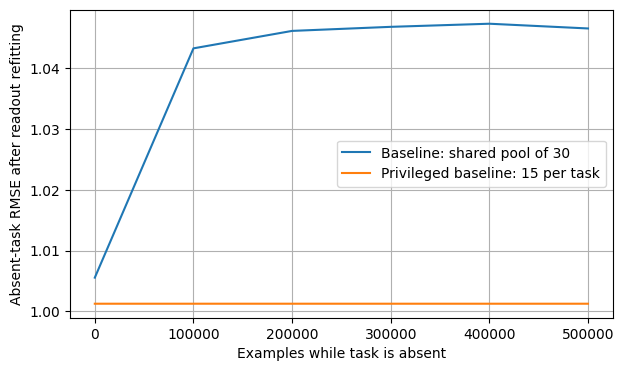

In [30]:
def allocation_initialize():
    from math import comb
    rate = float(np.exp(-8.))  # Match standardized 01a/01b.
    learner, teachers, keys = ready(initialize(True, nseeds=5))
    def weights(seed, teacher):
        kl = jax.random.split(jax.random.PRNGKey(seed), 3)[1]
        k0, k1 = jax.random.split(kl)
        w0 = rate * jax.random.uniform(k0, (15,22), minval=-1., maxval=1.).at[:,-1].set(0.)
        w0 = w0.at[:10,:-1].set(teacher[0][0]).at[:10,-1].set(-2.)
        w1 = rate * jax.random.uniform(k1, (30,16), minval=-1., maxval=1.).at[:,-1].set(0.)
        return w0, w1, jnp.zeros((20,31))
    w = jax.vmap(weights)(jnp.arange(5), teachers)
    means = jax.vmap(lambda a: (a[:,:-1]@CALIBRATION.T+a[:,-1,None]>0).mean(1))(w[0])
    means = means.at[:,:10].set(sum(comb(21,k) for k in range(12,22))/2**21)
    optimizer = optax_idbd(meta_lr=META_RATE,init_lr=rate,autostep=True,tau=1e4,version='squared_inputs')
    return learner._replace(weights=w,opt=jax.vmap(optimizer.init)(w),means=(means,learner.means[1])), teachers, keys


def allocation_01_update(l,x,y,task):
    def loss(w):
        lower=(ltu(w[0][:,:-1]@x+w[0][:,-1])-l.means[0])/jnp.sqrt(jnp.maximum(l.means[0]*(1-l.means[0]),VAR_FLOOR))
        source=jnp.append(lower,1.);z=w[1]@source;bits=ltu(z)
        mean=l.means[1]+EMA_RATE*(jax.lax.stop_gradient(bits)-l.means[1])
        sigmoid=jax.nn.sigmoid(z)
        derivative=jax.lax.stop_gradient((sigmoid*(1-sigmoid))[:,None]*source)
        slope=l.slopes[1]+EMA_RATE*(derivative-l.slopes[1])
        correction=jnp.sum(slope*w[1],axis=1)
        centered=jax.lax.stop_gradient(bits-mean)
        h=bits-mean+jax.lax.stop_gradient(correction)-correction
        cov=l.covs[1]+EMA_RATE*(centered[:,None]*(derivative-slope)-l.covs[1])
        var=mean*(1-mean);floor=jnp.maximum(var,VAR_FLOOR)
        change=jnp.sum(cov*w[1],axis=1)
        h=(h-centered*jnp.where(var>VAR_FLOOR,(change-jax.lax.stop_gradient(change))/floor,0.))/jnp.sqrt(floor)
        output_source=jnp.append(h,1.)
        error=(w[-1]@output_source).reshape(2,OUTPUTS)[task]-y
        return .5*jnp.sum(error**2),((jnp.append(x,1.)[None],source[None],output_source[None]),mean,slope,cov)
    (_, (sources,mean,slope,cov)),g=jax.value_and_grad(loss,has_aux=True)(l.weights)
    g=(jnp.zeros_like(g[0]),*g[1:]);u,opt=OPT.update((g,None,sources),l.opt,l.weights)
    return Learner((l.weights[0],l.weights[1]+u[1],l.weights[2]+u[2]),opt,
                   (l.means[0],mean),(l.slopes[0],slope),(l.covs[0],cov))


@jax.jit
def allocation_refit(learners,teachers):
    def one(l,t):
        def features(x):
            for w,m in zip(l.weights[:-1],l.means):
                x=(ltu(w[:,:-1]@x+w[:,-1])-m)/jnp.sqrt(jnp.maximum(m*(1-m),VAR_FLOOR))
            return jnp.append(x,1.)
        x=jax.random.rademacher(jax.random.PRNGKey(899),(16384,INPUTS),dtype=jnp.float32)
        h=jax.vmap(features)(x)
        y=jax.vmap(lambda x:jax.vmap(lambda t:target(t,x))(t))(x).reshape(len(x),-1)
        w=jnp.linalg.lstsq(h,y,rcond=1e-5)[0].T
        return l._replace(weights=(*l.weights[:-1],w))
    return jax.vmap(jax.vmap(one,in_axes=(0,0)),in_axes=(0,None))(learners,teachers)


def allocation_reference():
    started=time.perf_counter()
    learner,teachers,keys=allocation_initialize()
    ls=repeat(learner,2);ks=jnp.stack([keys]*2)
    mask=(jnp.arange(20)[:,None]//10==jnp.arange(31)[None,:]//15)|(jnp.arange(31)[None,:]==30)
    @jax.jit
    def advance(ls,ks,task):
        def one(l,k,t,allocated):
            def sample(c,_):
                l,k=c;k,kx,kn=jax.random.split(k,3)
                x=jax.random.rademacher(kx,(INPUTS,),dtype=jnp.float32)
                y=target(jax.tree.map(lambda a:a[task],t),x)+jax.random.normal(kn,(OUTPUTS,))
                output=jnp.where(allocated & ~mask,0.,l.weights[-1])
                l=allocation_01_update(l._replace(weights=(*l.weights[:-1],output)),x,y,task)
                output=jnp.where(allocated & ~mask,0.,l.weights[-1])
                return (l._replace(weights=(*l.weights[:-1],output)),k),None
            return jax.lax.scan(sample,(l,k),None,length=10000)[0]
        return jax.vmap(jax.vmap(one,in_axes=(0,0,0,None)),in_axes=(0,0,None,0))(ls,ks,teachers,jnp.array([False,True]))
    for i in range(160):ls,ks=ready(advance(ls,ks,jnp.asarray(i%2)))
    scores=[];refits=[]
    for i in range(51):
        if i%10==0:
            scores.append(np.asarray(ready(evaluate(ls,teachers))))
            refits.append(np.asarray(ready(evaluate(allocation_refit(ls,teachers),teachers))))
        if i<50:ls,ks=ready(advance(ls,ks,jnp.asarray(0)))
    result=dict(scores=np.asarray(scores),refits=np.asarray(refits),seconds=time.perf_counter()-started)
    assert np.isfinite(result['refits']).all()
    print('Shared pool / allocated; initial refitted RMSE:',result['refits'][0].mean(1))
    print('Final actual-readout RMSE:',result['scores'][-1].mean(1))
    print('Final refitted RMSE:',result['refits'][-1].mean(1))
    print(f'Runtime: {result["seconds"]:.1f}s')
    return result


allocation_result = allocation_reference()
fig,ax=plt.subplots(figsize=(7,4))
for i,label in enumerate(['Baseline: shared pool of 30','Privileged baseline: 15 per task']):
    ax.plot(np.arange(6)*100_000,allocation_result['refits'][:,i,:,1].mean(1),label=label)
ax.set(xlabel='Examples while task is absent',ylabel='Absent-task RMSE after readout refitting')
ax.grid();ax.legend();plt.show()


**The new backward rule was not a pure bug fix.** In 01, a unit's current error multiplies a corrected local derivative. In the new rule, stored average errors are subtracted from its current error. With exact stationary expectations these can give the same average update, but they give different individual updates and different histories for Autostep.

A concrete failure of equivalence: disconnect every hidden unit from the active readout and make the current prediction correct. The current hidden gradient is exactly zero. Historical error traces still move hidden weights under the new rule. The constructed check below verifies this in 30 cases; the 01 rule makes zero changes. The same effect was also checked using traces from acquired learners. This does not quantify its contribution to all observed forgetting, but it proves that the new rule changes online learning even in one trainable layer. The earlier switch-after-acquisition control could not detect its effect on learning the representation.


In [31]:
# Constructed check: historical error traces must not be confused with a current gradient.
l,_,_=ready(initialize(True,nseeds=30))
x=jax.random.rademacher(jax.random.PRNGKey(12),(30,INPUTS),dtype=jnp.float32)
y=jnp.zeros((30,OUTPUTS))
traces=(jnp.full_like(l.means[1],.1),jnp.zeros_like(l.means[1]))
# All output weights start at zero, so the current loss and every true hidden gradient are zero.
old=ready(jax.vmap(allocation_01_update,in_axes=(0,0,0,None))(l,x,y,jnp.asarray(0)))
new,_=ready(jax.vmap(fixed_lower_update,in_axes=(0,0,0,0,None))(l,traces,x,y,jnp.asarray(0)))
old_change=np.asarray(jnp.sqrt(jnp.mean((old.weights[1]-l.weights[1])**2,axis=(1,2))))
new_change=np.asarray(jnp.sqrt(jnp.mean((new.weights[1]-l.weights[1])**2,axis=(1,2))))
assert (old_change==0).all() and (new_change>0).all()
print('01 rule: zero hidden-weight change in all 30 cases.')
print('Error-trace rule: nonzero hidden-weight change in all 30 cases.')


01 rule: zero hidden-weight change in all 30 cases.
Error-trace rule: nonzero hidden-weight change in all 30 cases.


**Simple explanation.** The shared learner uses some of the same upper units to help fit both tasks. Further fitting one task changes those units and harms the other. Standardization can keep unused features alive, but it does not reserve features that the current task is still using. The allocation reference learns both tasks nearly perfectly and retains them in the same space, so this is interference over how capacity is used, not insufficient representational capacity.

With 01's update, the shared-pool absent task goes from refitted RMSE 1.006 to 1.047; assigning fifteen units per task gives 1.001 → 1.001. The allocated learner's active-task actual RMSE is 1.002, so preservation does not require poor active learning in this reference. It is a privileged diagnostic, not a proposed task-aware algorithm.

For an incremental extension of 01, preserve its own-weight update and investigate the missing upstream propagation path separately. Do not treat the current error-trace replacement as a validated equivalent of 01. The extra research question exposed by the small network is how to preserve learned computations while learning chooses which units to reuse or replace. These experiments establish the interference mechanism and a successful capacity baseline; they do not establish indefinite retention or uniquely explain every optimization difference between task generators.


## Long absence with 01's update: the small loss plateaus

The important criterion is continuing deterioration, not a small initial loss. Extend the original-01-update shared-pool and allocated controls from 500k to 4M absent examples, with the same five paired seeds and uninterrupted learner/optimizer state. The continuation takes 95 seconds on GPU. Readout refitting is an evaluation only: a fresh readout is fit to noiseless labels with hidden features frozen, on separate data from evaluation. It does not train the absent task's features or feed into subsequent learning.

| Absent examples | Shared pool: absent-task RMSE after refitting |
| --- | ---: |
| 0 | 1.006 |
| 0.5M | 1.047 |
| 1M | 1.049 |
| 2M | 1.049 |
| 4M | 1.049 |

The actual frozen old readout also plateaus, around 1.12. Most teacher features have distinct best-matching learner units across tasks: only 0–2 of the ten active-task teacher features share their best match with an absent-task feature in each seed, both before and after the absence. This is a complementary diagnostic, not a proof that all readout connections are task-specific.

**Revised conclusion:** this small fixed-lower-feature experiment with 01's update does not demonstrate harmful continuing forgetting. It shows a small settling loss followed by a plateau over the tested horizon, consistent with the behavior sought in 01. The earlier four-million-step deterioration used the changed error-trace rule and cannot be used to claim the same trend for 01's update. Indefinite stability remains unproven. The next depth experiment should preserve the 01 own-weight update and isolate what happens when lower features are allowed to change.


Absence steps: [ 500000 1000000 1500000 2000000 2500000 3000000 3500000 4000000]
Shared pool refitted [active, absent]: [[1.0020682 1.0465789]
 [1.001109  1.0490983]
 [1.0011919 1.0497139]
 [1.0007678 1.0488336]
 [1.0008615 1.0483409]
 [1.0009019 1.0481931]
 [1.0006479 1.0487837]
 [1.0003216 1.0488352]]
Continuation: 94.6s
Mean best-feature correlation [active, absent], before / after: [0.9265265  0.99439573] [0.9901201 0.9425705]
Active teacher features sharing their best learner unit with an absent feature, per seed: [2 1 0 0 2] [2 2 0 0 1]


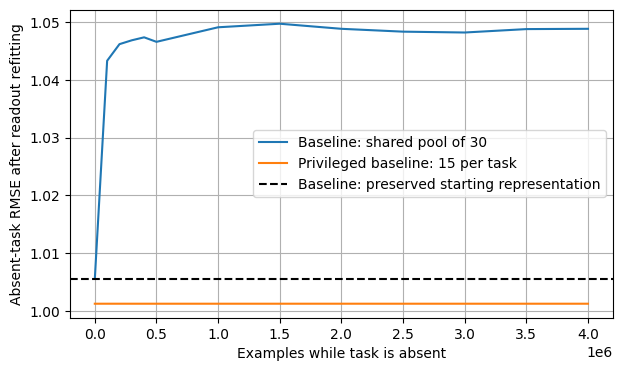

In [32]:
def extend_allocation(result):
    started=time.perf_counter()
    ls,ks,teachers=result['final'],result['keys'],result['teachers']
    mask=(jnp.arange(20)[:,None]//10==jnp.arange(31)[None,:]//15)|(jnp.arange(31)[None,:]==30)
    @jax.jit
    def advance(ls,ks):
        def one(l,k,t,allocated):
            def sample(c,_):
                l,k=c;k,kx,kn=jax.random.split(k,3)
                x=jax.random.rademacher(kx,(INPUTS,),dtype=jnp.float32)
                y=target(jax.tree.map(lambda a:a[0],t),x)+jax.random.normal(kn,(OUTPUTS,))
                output=jnp.where(allocated & ~mask,0.,l.weights[-1])
                l=allocation_01_update(l._replace(weights=(*l.weights[:-1],output)),x,y,jnp.asarray(0))
                output=jnp.where(allocated & ~mask,0.,l.weights[-1])
                return (l._replace(weights=(*l.weights[:-1],output)),k),None
            return jax.lax.scan(sample,(l,k),None,length=10000)[0]
        return jax.vmap(jax.vmap(one,in_axes=(0,0,0,None)),in_axes=(0,0,None,0))(ls,ks,teachers,jnp.array([False,True]))
    times=[500_000];scores=[result['scores'][-1]];refits=[result['refits'][-1]]
    for i in range(350):
        ls,ks=ready(advance(ls,ks))
        if (i+1)%50==0:
            times.append(500_000+(i+1)*10_000)
            scores.append(np.asarray(ready(evaluate(ls,teachers))))
            refits.append(np.asarray(ready(evaluate(allocation_refit(ls,teachers),teachers))))
    result=dict(times=np.asarray(times),scores=np.asarray(scores),refits=np.asarray(refits),
                final=ls,keys=ks,teachers=teachers,seconds=time.perf_counter()-started)
    assert np.isfinite(result['refits']).all()
    print('Absence steps:',result['times'])
    print('Shared pool refitted [active, absent]:',result['refits'][:,0].mean(1))
    print(f'Continuation: {result["seconds"]:.1f}s')
    return result


old_rule_long = extend_allocation(allocation_result)
fig,ax=plt.subplots(figsize=(7,4))
times=np.concatenate((np.arange(6)*100_000,old_rule_long['times'][1:]))
values=np.concatenate((allocation_result['refits'],old_rule_long['refits'][1:]))
for i,label in enumerate(['Baseline: shared pool of 30','Privileged baseline: 15 per task']):
    ax.plot(times,values[:,i,:,1].mean(1),label=label)
ax.axhline(values[0,0,:,1].mean(),color='black',linestyle='--',label='Baseline: preserved starting representation')
ax.set(xlabel='Examples while task is absent',ylabel='Absent-task RMSE after readout refitting')
ax.grid();ax.legend();plt.show()

@jax.jit
def matches(ls,ts):
 x=jax.random.rademacher(jax.random.PRNGKey(926),(4096,INPUTS),dtype=jnp.float32)
 def one(l,t):
  lower=ltu(l.weights[0][:,:-1]@x.T+l.weights[0][:,-1,None])
  normalized=(lower-l.means[0][:,None])/jnp.sqrt(jnp.maximum(l.means[0]*(1-l.means[0]),VAR_FLOOR))[:,None]
  h=ltu(l.weights[1][:,:-1]@normalized+l.weights[1][:,-1,None])
  truth=(jnp.einsum('tij,jn->tin',t[1],lower[:10])>t[2][...,None]).reshape(20,-1).astype(jnp.float32)
  def norm(a):
   a=a-a.mean(1,keepdims=True)
   return a/jnp.maximum(jnp.linalg.norm(a,axis=1,keepdims=True),1e-8)
  corr=jnp.abs(norm(truth)@norm(h).T)
  best=corr.argmax(1)
  overlap=jnp.sum(jnp.any(best[:10,None]==best[None,10:],axis=1))
  return corr.max(1).reshape(2,10),overlap
 return jax.vmap(one)(ls,ts)

start_matches=ready(matches(jax.tree.map(lambda a:a[0],allocation_result['anchor']),old_rule_long['teachers']))
end_matches=ready(matches(jax.tree.map(lambda a:a[0],old_rule_long['final']),old_rule_long['teachers']))
print('Mean best-feature correlation [active, absent], before / after:',
      np.asarray(start_matches[0]).mean((0,2)),np.asarray(end_matches[0]).mean((0,2)))
print('Active teacher features sharing their best learner unit with an absent feature, per seed:',
      start_matches[1],end_matches[1])


## Appendix: reuse experiments (deferred)

Use 30 paired seeds. First learn two tasks with shared lower features for 1.6M examples, alternating observed readouts every example, so both tasks are well learned at the branching point. The initial learner has 15 lower and 30 upper units. Add a complete spare module of 15 lower and 15 upper units and a zero-initialized third readout. All four simulated learners have the same resulting 30 → 45 architecture.

Introduce one of two new tasks:

- **New composition:** a new upper teacher and readout use exactly the old lower features.
- **Small variation:** change the sign of one incoming weight of one lower teacher unit; retain the upper teacher and readout of old task 2. Old task 2 still needs the original feature.

Compare fresh learning, ordinary fine-tuning from the learned model, freezing all hidden units, and protecting the original units while training the spare module. Protection freezes both weights and normalization state; old upper units have no connections from the new lower units, and old readouts have zero connections from the new upper units. New upper units can read both old and new lower features. This is a **privileged capacity-allocation reference**: the experiment supplies the consolidation time and protected subnetwork.

A fifth, constructive reference keeps the original model untouched and fine-tunes a copy. For the new task its learning curve is exactly ordinary fine-tuning's; old tasks are answered by the untouched model. It therefore needs no additional independent training run. It costs a second feature extractor and known task routing. It is not an equal-memory comparison or evidence of automatic consolidation.


In [11]:
@jax.jit
def expanded(old,fresh,key):
    # Add fifteen lower units; the 3-head initialization already has fifteen spare upper units.
    k1,k2=jax.random.split(key)
    w1=jnp.concatenate((fresh.weights[0],INIT_RATE*jax.random.uniform(k1,(15,INPUTS+1),minval=-1.,maxval=1.).at[:,-1].set(0.)))
    w2=INIT_RATE*jax.random.uniform(k2,(45,31),minval=-1.,maxval=1.).at[:,-1].set(0.)
    w2=w2.at[:,:15].set(fresh.weights[1][:,:15])
    weights=(w1,w2,fresh.weights[2])
    fresh=Learner(weights,OPT.init(weights),tuple(jnp.full(len(w),.5) for w in weights[:-1]),tuple(jnp.zeros_like(w).at[:,-1].set(.25) for w in weights[:-1]),tuple(jnp.zeros_like(w) for w in weights[:-1]))
    def embed(a,b):
        return b.at[:a.shape[0],:a.shape[1]-1].set(a[:,:-1]).at[:a.shape[0],-1].set(a[:,-1])
    # Existing computations do not depend on newly added units.
    base=list(fresh.weights)
    base[1]=base[1].at[:30,15:30].set(0.)
    weights=tuple(embed(a,b) for a,b in zip(old.weights,base))
    opt=fresh.opt._replace(**{name:tuple(embed(a,b) for a,b in zip(getattr(old.opt,name),getattr(fresh.opt,name))) for name in ('beta','h','v')})
    means=tuple(b.at[:a.shape[0]].set(a) for a,b in zip(old.means,fresh.means))
    slopes=tuple(embed(a,b) for a,b in zip(old.slopes,fresh.slopes))
    covs=tuple(embed(a,b) for a,b in zip(old.covs,fresh.covs))
    return fresh,Learner(weights,opt,means,slopes,covs)


In [12]:
def protect_forward(weights, x, learner, mode):
    sources, means, slopes, covs = [], [], [], []
    for layer, (w, mean, slope, cov) in enumerate(zip(weights[:-1], learner.means, learner.slopes, learner.covs)):
        frozen = (mode == 2) | ((mode == 6) & (jnp.arange(len(w)) < (15, 30)[layer]))
        rate = jnp.where(frozen, 0., EMA_RATE)
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        bits = ltu(z)
        mean = mean + rate * (jax.lax.stop_gradient(bits) - mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient((sigmoid * (1 - sigmoid))[:, None] * source)
        slope = slope + rate[:, None] * (derivative - slope)
        correction = jnp.sum(slope * w, axis=1)
        centered = jax.lax.stop_gradient(bits - mean)
        h = bits - mean + (jax.lax.stop_gradient(correction) - correction)
        cov = cov + rate[:, None] * (centered[:, None] * (derivative - slope) - cov)
        var = mean * (1 - mean)
        change = jnp.sum(cov * w, axis=1)
        floored = jnp.maximum(var, VAR_FLOOR)
        h = h - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / floored, 0.)
        x = h / jnp.sqrt(floored)
        means.append(mean); slopes.append(slope); covs.append(cov)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes), tuple(covs))


def protect_update(learner, anchor, x, y, task, mode):
    # 0: ordinary training. 2: preserved hidden representation. 5: preserve old predictions.
    def loss(weights):
        prediction, aux = protect_forward(weights, x, learner, mode)
        prediction = prediction.reshape(-1, OUTPUTS)
        active = .5 * jnp.sum((prediction[task] - y) ** 2)
        objective = active
        if anchor is not None:
            old = jax.lax.stop_gradient(predict(anchor, x).reshape(-1, OUTPUTS))
            inactive = (jnp.arange(prediction.shape[0]) != task)[:, None]
            preservation = .5 * jnp.sum(jnp.where(inactive, (prediction - old) ** 2, 0.))
            objective = objective + jnp.where(mode == 5, preservation, 0.)
        return objective, (aux, 2 * active / OUTPUTS)
    (_, ((sources, *stats), mse)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    # Inactive readouts stay fixed, including under the preservation objective.
    active_rows = (jnp.arange(grads[-1].shape[0]) // OUTPUTS == task)[:, None]
    grads = (*grads[:-1], jnp.where(active_rows, grads[-1], 0.))
    grads = tuple(jnp.where(((mode == 6) & (jnp.arange(g.shape[0]) < n))[:, None], 0., g) for g, n in zip(grads[:-1], (15, 30))) + (grads[-1],)
    updates, opt = OPT.update((grads, None, sources), learner.opt, learner.weights)
    weights = jax.tree.map(jnp.add, learner.weights, updates)
    weights = tuple(jnp.where(mode == 2, a, b) for a, b in zip(learner.weights[:-1], weights[:-1])) + (weights[-1],)
    return Learner(weights, opt, *stats), mse



@partial(jax.jit, static_argnames=('steps', 'active', 'period'))
def train_protected(learners, anchor, teachers, keys, steps, active, modes, period=10_000):
    def one(learner, saved, teacher, key, mode):
        def sample(carry, i):
            learner, key = carry
            key, kx, kn = jax.random.split(key, 3)
            x = jax.random.rademacher(kx, (INPUTS,), dtype=jnp.float32)
            task = (i // period) % teacher[0].shape[0] if active == 'all' else jnp.asarray(int(active))
            y = target(jax.tree.map(lambda a: a[task], teacher), x) + jax.random.normal(kn, (OUTPUTS,))
            learner, mse = protect_update(learner, saved, x, y, task, mode)
            return (learner, key), mse
        def window(carry, i):
            carry, mse = jax.lax.scan(sample, carry, i * 1000 + jnp.arange(1000))
            return carry, mse.mean()
        (learner, key), mse = jax.lax.scan(window, (learner, key), jnp.arange(steps // 1000))
        return learner, key, mse
    seed_batch = jax.vmap(one, in_axes=(0, 0, 0, 0, None))
    return jax.vmap(seed_batch, in_axes=(0, None, None, 0, 0))(learners, anchor, teachers, keys, modes)




In [14]:
def transfer(old, t, r, variation):
    start=time.perf_counter()
    nseeds=r.shape[0]
    f,_,_=ready(initialize(True,nseeds,3))
    fresh,learned=ready(jax.vmap(expanded)(old,f,jax.random.split(jax.random.PRNGKey(802),nseeds)))
    if variation:
        first=t[0][:,-1].at[:,0,0].multiply(-1)
        new=tuple(a[:,-1] for a in t[1:])
    else:
        first=t[0][:,0]
        new=jax.vmap(make_task)(jax.random.split(jax.random.PRNGKey(801),nseeds),first)
    teachers=(jnp.concatenate((t[0],first[:,None]),axis=1),*(jnp.concatenate((a,b[:,None]),axis=1) for a,b in zip(t[1:],new)))
    modes=jnp.array([0,0,2,6]);ls=jax.tree.map(lambda a,b:jnp.stack((a,b,b,b)),fresh,learned);rs=jnp.stack([r]*4)
    before=ls
    scores=[np.asarray(ready(evaluate(ls,teachers)))];curves=[]
    for _ in range(10):
        ls,rs,m=ready(train_protected(ls,None,teachers,rs,50000,'2',modes));curves.append(np.asarray(m));scores.append(np.asarray(ready(evaluate(ls,teachers))))
    # Exact checks on the protected computation, not just favorable average performance.
    for i,n in enumerate((15,30)):
        np.testing.assert_array_equal(np.asarray(before.weights[i][3,:,:n]),np.asarray(ls.weights[i][3,:,:n]))
        np.testing.assert_array_equal(np.asarray(before.means[i][3,:,:n]),np.asarray(ls.means[i][3,:,:n]))
    np.testing.assert_array_equal(np.asarray(before.weights[-1][3,:,:20]),np.asarray(ls.weights[-1][3,:,:20]))
    np.testing.assert_array_equal(scores[0][3,:,:2],scores[-1][3,:,:2])
    assert np.any(np.asarray(before.weights[0][3,:,15:])!=np.asarray(ls.weights[0][3,:,15:]))
    result={'variation':variation,'labels':['Fresh (baseline)','Pretrained (baseline)','Frozen hidden layers (reference)','Protected units + spare module (reference)'],'mse':np.concatenate(curves,axis=2),'scores':np.array(scores),'seconds':time.perf_counter()-start}
    assert np.isfinite(result['mse']).all() and np.isfinite(result['scores']).all()
    print('Variation' if variation else 'New composition', f'{result["seconds"]:.1f}s',
          'final task RMSE [old 1, old 2, new]:\n', result['scores'][-1].mean(1))
    return result


In [15]:
transfer_results = {variation: transfer(old, teachers, keys, variation) for variation in (False, True)}


New composition 38.0s final task RMSE [old 1, old 2, new]:
 [[1.9664358 1.9664077 1.0719453]
 [1.404206  1.4024489 1.0243391]
 [1.0346348 1.0386146 1.3285483]
 [1.0346348 1.0386146 1.0363994]]
Variation 25.8s final task RMSE [old 1, old 2, new]:
 [[1.9664358 1.9664077 1.0807147]
 [1.2463032 1.1845038 1.0135056]
 [1.0346348 1.0386146 1.1639444]
 [1.0346348 1.0386146 1.1303768]]


**A smaller copying control.** For the lower-feature variation, initialize the spare lower units with copies of the learned lower units, including their normalization state. Leave spare upper units and optimizer histories fresh. Capacity and training are unchanged. This checks whether copying only the lower computation is enough.


In [17]:
def copy_lower_control(old,t,r):
    start=time.perf_counter()
    f,_,_=ready(initialize(True,r.shape[0],3))
    _,learned=ready(jax.vmap(expanded)(old,f,jax.random.split(jax.random.PRNGKey(802),r.shape[0])))
    def copy_lower(a):
        return a.at[:,15:].set(a[:,:15])
    weights=(copy_lower(learned.weights[0]),*learned.weights[1:])
    means=(copy_lower(learned.means[0]),learned.means[1])
    slopes=(copy_lower(learned.slopes[0]),learned.slopes[1])
    covs=(copy_lower(learned.covs[0]),learned.covs[1])
    # Copy the learned computation; the new units start with fresh optimizer history.
    learned=Learner(weights,learned.opt,means,slopes,covs)
    first=t[0][:,-1].at[:,0,0].multiply(-1)
    new=tuple(a[:,-1] for a in t[1:])
    teachers=(jnp.concatenate((t[0],first[:,None]),axis=1),*(jnp.concatenate((a,b[:,None]),axis=1) for a,b in zip(t[1:],new)))
    ls=repeat(learned,1); rs=r[None]
    scores=[np.asarray(ready(evaluate(ls,teachers)))]; curves=[]
    for _ in range(10):
        ls,rs,m=ready(train_protected(ls,None,teachers,rs,50000,'2',jnp.array([6])))
        curves.append(np.asarray(m)); scores.append(np.asarray(ready(evaluate(ls,teachers))))
    np.testing.assert_array_equal(scores[0][0,:,:2],scores[-1][0,:,:2])
    result=dict(mse=np.concatenate(curves,axis=2),scores=np.asarray(scores),seconds=time.perf_counter()-start)
    return result

copy_lower_result = copy_lower_control(old, teachers, keys)
print("Copied lower features; old 1, old 2, new:", copy_lower_result["scores"][-1].mean(1))


Copied lower features; old 1, old 2, new: [[1.0346329 1.0386494 1.1227506]]


Bands are approximate 95% confidence intervals over 30 seeds.


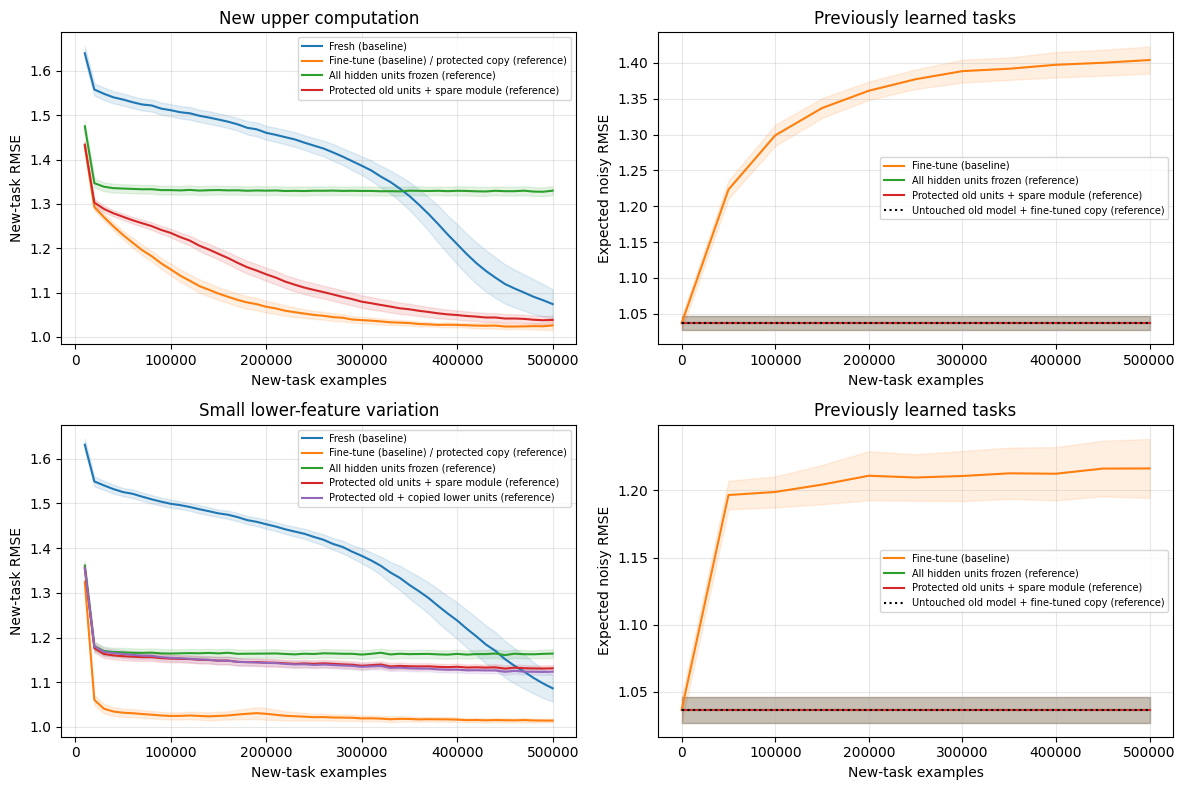

In [18]:
def mean_band(ax, x, values, label, **kwargs):
    mean = values.mean(0)
    error = 1.96 * values.std(0, ddof=1) / np.sqrt(len(values))
    line, = ax.plot(x, mean, label=label, **kwargs)
    ax.fill_between(x, mean-error, mean+error, color=line.get_color(), alpha=.12)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (variation, result) in enumerate(transfer_results.items()):
    title = 'Small lower-feature variation' if variation else 'New upper computation'
    mse = result['mse'].reshape(4, 30, -1, 10).mean(-1)
    x = np.arange(1, mse.shape[-1]+1)*10_000
    labels = ('Fresh (baseline)', 'Fine-tune (baseline) / protected copy (reference)',
              'All hidden units frozen (reference)', 'Protected old units + spare module (reference)')
    for i, label in enumerate(labels):
        mean_band(axes[row, 0], x, np.sqrt(mse[i]), label, color=f'C{i}')
    if variation:
        copied_mse = copy_lower_result['mse'].reshape(30, -1, 10).mean(-1)
        mean_band(axes[row, 0], x, np.sqrt(copied_mse),
                  'Protected old + copied lower units (reference)', color='C4')
    scores = result['scores']
    xq = np.arange(len(scores))*50_000
    for i in (1, 2, 3):
        old_rmse = np.sqrt((scores[:, i, :, :2]**2).mean(-1)).T
        mean_band(axes[row, 1], xq, old_rmse, ('Fine-tune (baseline)' if i == 1 else labels[i]), color=f'C{i}')
    # Exact routed-copy reference: old model unchanged, new predictions equal fine-tuning.
    old_rmse = np.sqrt((scores[0, 1, :, :2]**2).mean(-1))
    mean_band(axes[row, 1], xq, np.repeat(old_rmse[:, None], len(xq), axis=1),
              'Untouched old model + fine-tuned copy (reference)', ls=':', color='black')
    axes[row, 0].set(title=title, xlabel='New-task examples', ylabel='New-task RMSE')
    axes[row, 1].set(title='Previously learned tasks', xlabel='New-task examples', ylabel='Expected noisy RMSE')
for ax in axes.flat:
    ax.grid(True, alpha=.3)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
print('Bands are approximate 95% confidence intervals over 30 seeds.')


## Appendix: exploratory task-count and recurrence sweep

Keep initial learning and capacity fixed. Take five seeds from the same acquired two-task models and expand each learner to 15 → 135 units with nine readouts. All configurations have enough capacity for both old tasks and seven incoming tasks. Incoming tasks use the same lower teacher features and independently generated upper computations. No incoming task is trained before this test.

Train on pools of 1, 3 or 7 incoming tasks, sampled uniformly. Compare both 200k total examples and 200k expected examples **per incoming task**; the latter necessarily makes absence longer for larger pools. Separately, with one incoming task, return to the old task independently with probability 0, .001, .01 or .1 for 200k total examples. All other readouts stay fixed. The preserved learned model supplies the constant old-task reference.

This tests interference from **newly arriving** problems. It does not establish scaling for a larger pool of already-mastered recurring tasks, or isolate prior recurrence history at a fixed later absence. Five paired seeds per configuration; no uncertainty bands.


In [20]:
def scaling(old,t,r):
    old,t,r=jax.tree.map(lambda a:a[:5],(old,t,r))
    start=time.perf_counter()
    f,_,_=ready(initialize(True,5,9))
    def embed(a,b):
        return b.at[:a.shape[0],:a.shape[1]-1].set(a[:,:-1]).at[:a.shape[0],-1].set(a[:,-1])
    def expand(a,b):
        weights=tuple(embed(x,y) for x,y in zip(a.weights,b.weights))
        opt=b.opt._replace(**{name:tuple(embed(x,y) for x,y in zip(getattr(a.opt,name),getattr(b.opt,name))) for name in ('beta','h','v')})
        means=tuple(y.at[:len(x)].set(x) for x,y in zip(a.means,b.means))
        slopes=tuple(embed(x,y) for x,y in zip(a.slopes,b.slopes))
        covs=tuple(embed(x,y) for x,y in zip(a.covs,b.covs))
        return Learner(weights,opt,means,slopes,covs)
    base=ready(jax.vmap(expand)(old,f))
    def extra(seed,first):
        return jax.vmap(make_task,in_axes=(0,None))(jax.random.split(jax.random.PRNGKey(seed+1000),7),first)
    new=jax.vmap(extra)(jnp.arange(5),t[0][:,0])
    teachers=(jnp.concatenate((t[0],jnp.repeat(t[0][:,:1],7,axis=1)),axis=1),*(jnp.concatenate((a,b),axis=1) for a,b in zip(t[1:],new)))
    pools=jnp.array([1,3,7,1,1,1]);freqs=jnp.array([0.,0.,0.,.001,.01,.1])
    @jax.jit
    def advance(ls,keys,teachers,pools,freqs):
        def one(l,key,t,pool,freq):
            def step(c,_):
                l,k=c; k,kx,kn,kt,kf=jax.random.split(k,5)
                x=jax.random.rademacher(kx,(INPUTS,),dtype=jnp.float32)
                task=jnp.where(jax.random.uniform(kf)<freq,1,2+jax.random.randint(kt,(),0,pool))
                y=target(jax.tree.map(lambda a:a[task],t),x)+jax.random.normal(kn,(OUTPUTS,))
                l,m=update(l,None,x,y,task,0)
                return (l,k),m
            def window(c,_):
                c,m=jax.lax.scan(step,c,None,length=1000)
                return c,m.mean()
            (l,k),m=jax.lax.scan(window,(l,key),None,length=50)
            return l,k,m
        return jax.vmap(jax.vmap(one,in_axes=(0,0,0,None,None)),in_axes=(0,0,None,0,0))(ls,keys,teachers,pools,freqs)
    ls=repeat(base,6);keys=jnp.stack([r]*6)
    scores=[np.asarray(ready(evaluate(ls,teachers)))];curves=[]
    for _ in range(4):
        ls,keys,m=ready(advance(ls,keys,teachers,pools,freqs));curves.append(np.asarray(m))
        scores.append(np.asarray(ready(evaluate(ls,teachers))))
    result=dict(pools=np.asarray(pools),freqs=np.asarray(freqs),scores=np.asarray(scores),mse=np.concatenate(curves,axis=2),seconds=time.perf_counter()-start)
    assert np.isfinite(result['scores']).all()
    # Continue the larger pools until each incoming task has 200k expected examples.
    ls=jax.tree.map(lambda a:a[1:3],ls);keys=keys[1:3]
    pools=jnp.array([3,7]);freqs=jnp.zeros(2)
    continued=[result['scores'][-1,1:3]]
    for _ in range(24):
        ls,keys,_=ready(advance(ls,keys,teachers,pools,freqs))
        continued.append(np.asarray(ready(evaluate(ls,teachers))))
    result['continued_scores']=np.asarray(continued)
    result['seconds']=time.perf_counter()-start
    assert np.isfinite(result['continued_scores']).all()
    return result

scaling_result = scaling(old, teachers, keys)
print(f"Scaling sweep: {scaling_result['seconds']:.1f}s")


Scaling sweep: 69.7s


1 incoming tasks; RMSE at matched per-task exposure: 1.386
3 incoming tasks; RMSE at matched per-task exposure: 1.382
7 incoming tasks; RMSE at matched per-task exposure: 1.287
RMSE at 200k total examples, pools 1/3/7: [1.3860674 1.2438291 1.1232399]
RMSE by return probability 0/.001/.01/.1: [1.3860674 1.3720148 1.3086535 1.1398687]


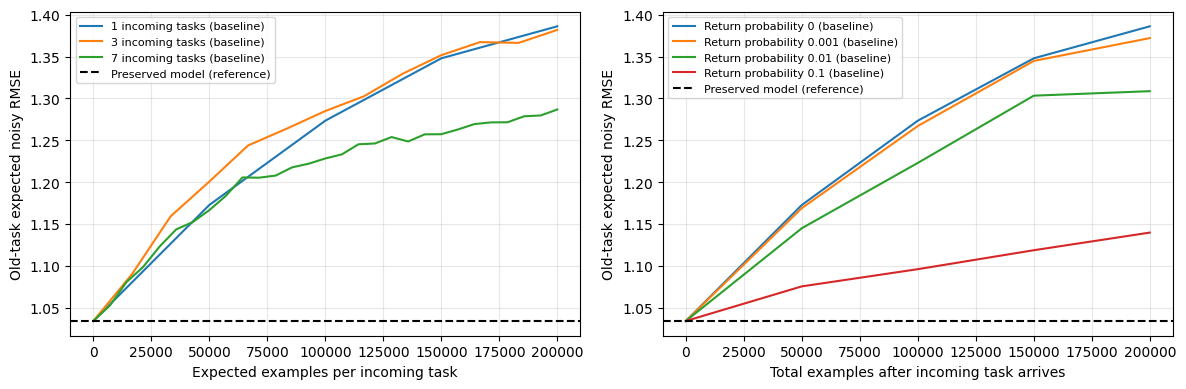

In [21]:
result = scaling_result
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
reference = result['scores'][0, 0, :, 1].mean()
for i, pool in enumerate((1, 3, 7)):
    values = result['scores'][:, i, :, 1]
    if pool > 1:
        extra = result['continued_scores'][1:, i-1, :, 1]
        values = np.concatenate((values, extra))[:4*pool+1]
    axes[0].plot(np.arange(len(values))*50_000/pool, values.mean(1),
                 label=f'{pool} incoming tasks (baseline)')
    print(f'{pool} incoming tasks; RMSE at matched per-task exposure: {values[-1].mean():.3f}')
for i in (0, 3, 4, 5):
    axes[1].plot(np.arange(5)*50_000, result['scores'][:, i, :, 1].mean(1),
                 label=f'Return probability {result["freqs"][i]:g} (baseline)')
print('RMSE at 200k total examples, pools 1/3/7:', result['scores'][-1,:3,:,1].mean(1))
print('RMSE by return probability 0/.001/.01/.1:', result['scores'][-1,[0,3,4,5],:,1].mean(1))
for ax in axes:
    ax.axhline(reference, color='black', ls='--', label='Preserved model (reference)')
    ax.set_ylabel('Old-task expected noisy RMSE')
    ax.grid(True, alpha=.3); ax.legend(fontsize=8)
axes[0].set_xlabel('Expected examples per incoming task')
axes[1].set_xlabel('Total examples after incoming task arrives')
fig.tight_layout()
plt.show()


## Status

Question 1 remains the priority. The new controls above qualify the earlier interpretation: more practical capacity removed the shared-feature task loss, but a smaller gap remains with separate lower features. That gap is sensitive to target noise and lower-layer changes. A separate check exposed an incomplete normalization gradient. No learning gate has been added. The reuse and incoming-task studies remain exploratory background, not the next step.
